# **New York City Yellow Taxi Data**

## Objective
In this case study you will be learning exploratory data analysis (EDA) with the help of a dataset on yellow taxi rides in New York City. This will enable you to understand why EDA is an important step in the process of data science and machine learning.

## **Problem Statement**
As an analyst at an upcoming taxi operation in NYC, you are tasked to use the 2023 taxi trip data to uncover insights that could help optimise taxi operations. The goal is to analyse patterns in the data that can inform strategic decisions to improve service efficiency, maximise revenue, and enhance passenger experience.

## Tasks
You need to perform the following steps for successfully completing this assignment:
1. Data Loading
2. Data Cleaning
3. Exploratory Analysis: Bivariate and Multivariate
4. Creating Visualisations to Support the Analysis
5. Deriving Insights and Stating Conclusions

---

**NOTE:** The marks given along with headings and sub-headings are cumulative marks for those particular headings/sub-headings.<br>

The actual marks for each task are specified within the tasks themselves.

For example, marks given with heading *2* or sub-heading *2.1* are the cumulative marks, for your reference only. <br>

The marks you will receive for completing tasks are given with the tasks.

Suppose the marks for two tasks are: 3 marks for 2.1.1 and 2 marks for 3.2.2, or
* 2.1.1 [3 marks]
* 3.2.2 [2 marks]

then, you will earn 3 marks for completing task 2.1.1 and 2 marks for completing task 3.2.2.


---

## Data Understanding
The yellow taxi trip records include fields capturing pick-up and drop-off dates/times, pick-up and drop-off locations, trip distances, itemized fares, rate types, payment types, and driver-reported passenger counts.

The data is stored in Parquet format (*.parquet*). The dataset is from 2009 to 2024. However, for this assignment, we will only be using the data from 2023.

The data for each month is present in a different parquet file. You will get twelve files for each of the months in 2023.

The data was collected and provided to the NYC Taxi and Limousine Commission (TLC) by technology providers like vendors and taxi hailing apps. <br>

You can find the link to the TLC trip records page here: https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page

###  Data Description
You can find the data description here: [Data Dictionary](https://www.nyc.gov/assets/tlc/downloads/pdf/data_dictionary_trip_records_yellow.pdf)

**Trip Records**



|Field Name       |description |
|:----------------|:-----------|
| VendorID | A code indicating the TPEP provider that provided the record. <br> 1= Creative Mobile Technologies, LLC; <br> 2= VeriFone Inc. |
| tpep_pickup_datetime | The date and time when the meter was engaged.  |
| tpep_dropoff_datetime | The date and time when the meter was disengaged.   |
| Passenger_count | The number of passengers in the vehicle. <br> This is a driver-entered value. |
| Trip_distance | The elapsed trip distance in miles reported by the taximeter. |
| PULocationID | TLC Taxi Zone in which the taximeter was engaged |
| DOLocationID | TLC Taxi Zone in which the taximeter was disengaged |
|RateCodeID |The final rate code in effect at the end of the trip.<br> 1 = Standard rate <br> 2 = JFK <br> 3 = Newark <br>4 = Nassau or Westchester <br>5 = Negotiated fare <br>6 = Group ride |
|Store_and_fwd_flag |This flag indicates whether the trip record was held in vehicle memory before sending to the vendor, aka “store and forward,” because the vehicle did not have a connection to the server.  <br>Y= store and forward trip <br>N= not a store and forward trip |
|Payment_type| A numeric code signifying how the passenger paid for the trip. <br> 1 = Credit card <br>2 = Cash <br>3 = No charge <br>4 = Dispute <br>5 = Unknown <br>6 = Voided trip |
|Fare_amount| The time-and-distance fare calculated by the meter. <br>Extra Miscellaneous extras and surcharges.  Currently, this only includes the 0.50 and 1 USD rush hour and overnight charges. |
|MTA_tax |0.50 USD MTA tax that is automatically triggered based on the metered rate in use. |
|Improvement_surcharge | 0.30 USD improvement surcharge assessed trips at the flag drop. The improvement surcharge began being levied in 2015. |
|Tip_amount |Tip amount – This field is automatically populated for credit card tips. Cash tips are not included. |
| Tolls_amount | Total amount of all tolls paid in trip.  |
| total_amount | The total amount charged to passengers. Does not include cash tips. |
|Congestion_Surcharge |Total amount collected in trip for NYS congestion surcharge. |
| Airport_fee | 1.25 USD for pick up only at LaGuardia and John F. Kennedy Airports|

Although the amounts of extra charges and taxes applied are specified in the data dictionary, you will see that some cases have different values of these charges in the actual data.

**Taxi Zones**

Each of the trip records contains a field corresponding to the location of the pickup or drop-off of the trip, populated by numbers ranging from 1-263.

These numbers correspond to taxi zones, which may be downloaded as a table or map/shapefile and matched to the trip records using a join.

This is covered in more detail in later sections.

---

## **1** Data Preparation

<font color = red>[5 marks]</font> <br>

### Import Libraries

In [613]:
# Import warnings
import warnings
warnings.filterwarnings("ignore")

In [615]:
# Import the libraries you will be using for analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [617]:
# Recommended versions
# numpy version: 1.26.4
# pandas version: 2.2.2
# matplotlib version: 3.10.0
# seaborn version: 0.13.2

# Check versions
print("numpy version:", np.__version__)
print("pandas version:", pd.__version__)
print("matplotlib version:", plt.matplotlib.__version__)
print("seaborn version:", sns.__version__)

numpy version: 1.26.4
pandas version: 2.2.2
matplotlib version: 3.9.2
seaborn version: 0.13.2


### **1.1** Load the dataset
<font color = red>[5 marks]</font> <br>

You will see twelve files, one for each month.

To read parquet files with Pandas, you have to follow a similar syntax as that for CSV files.

`df = pd.read_parquet('file.parquet')`

In [7]:
# Try loading one file
# df = pd.read_parquet('2023-1.parquet')
# df.info()

In [1311]:
df = pd.read_parquet(r'C:\Users\keert\OneDrive\Desktop\upGrad\C2 Data Toolkit\EDA\EDA Assignment\Datasets and Dictionary\trip_records\2023-1.parquet')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3041714 entries, 0 to 3066765
Data columns (total 19 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int64         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     object        
 7   PULocationID           int64         
 8   DOLocationID           int64         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  airport_fee            floa

How many rows are there? Do you think handling such a large number of rows is computationally feasible when we have to combine the data for all twelve months into one?

To handle this, we need to sample a fraction of data from each of the files. How to go about that? Think of a way to select only some portion of the data from each month's file that accurately represents the trends.

#### Sampling the Data
> One way is to take a small percentage of entries for pickup in every hour of a date. So, for all the days in a month, we can iterate through the hours and select 5% values randomly from those. Use `tpep_pickup_datetime` for this. Separate date and hour from the datetime values and then for each date, select some fraction of trips for each of the 24 hours.

To sample data, you can use the `sample()` method. Follow this syntax:

```Python
# sampled_data is an empty DF to keep appending sampled data of each hour
# hour_data is the DF of entries for an hour 'X' on a date 'Y'

sample = hour_data.sample(frac = 0.05, random_state = 42)
# sample 0.05 of the hour_data
# random_state is just a seed for sampling, you can define it yourself

sampled_data = pd.concat([sampled_data, sample]) # adding data for this hour to the DF
```

This *sampled_data* will contain 5% values selected at random from each hour.

Note that the code given above is only the part that will be used for sampling and not the complete code required for sampling and combining the data files.

Keep in mind that you sample by date AND hour, not just hour. (Why?)

---

**1.1.1** <font color = red>[5 marks]</font> <br>
Figure out how to sample and combine the files.

**Note:** It is not mandatory to use the method specified above. While sampling, you only need to make sure that your sampled data represents the overall data of all the months accurately.

In [18]:
# Sample the data
# It is recommmended to not load all the files at once to avoid memory overload

In [20]:
# from google.colab import drive
# drive.mount('/content/drive')

In [22]:
# Take a small percentage of entries from each hour of every date.
# Iterating through the monthly data:
#   read a month file -> day -> hour: append sampled data -> move to next hour -> move to next day after 24 hours -> move to next month file
# Create a single dataframe for the year combining all the monthly data

# Select the folder having data files
import os

# Select the folder having data files
os.chdir(r'C:\Users\keert\OneDrive\Desktop\upGrad\C2 Data Toolkit\EDA\EDA Assignment\Datasets and Dictionary\trip_records')

# Create a list of all the twelve files to read
file_list = os.listdir()

# initialise an empty dataframe
df = pd.DataFrame()


# iterate through the list of files and sample one by one:
for file_name in file_list:
    try:
        # file path for the current file
        file_path = os.path.join(os.getcwd(), file_name)

        # Reading the current file
        df_temp = pd.read_parquet(file_path)  # changed file_path to string

        df_temp['tpep_pickup_datetime'] = pd.to_datetime(df_temp['tpep_pickup_datetime'])

        df_temp['date'] = df_temp['tpep_pickup_datetime'].dt.date
        df_temp['hour'] = df_temp['tpep_pickup_datetime'].dt.hour


        # We will store the sampled data for the current date in this df by appending the sampled data from each hour to this
        # After completing iteration through each date, we will append this data to the final dataframe.
        sampled_data = pd.DataFrame()

        # Loop through dates and then loop through every hour of each date
        for date in df_temp['date'].unique():
            date_data = df_temp[df_temp['date'] == date]
            
            # Iterate through each hour of the selected date
            for hour in range(24):
                hour_data = date_data[date_data['hour'] == hour]
                
                # Sample 0.75% of the hourly data randomly
                if not hour_data.empty: 
                    sample = hour_data.sample(frac=0.0075, random_state=42)
                    
                # add data of this hour to the dataframe
                sampled_data = pd.concat([sampled_data, sample])
                
        # Concatenate the sampled data of all the dates to a single dataframe
        df = pd.concat([df, sampled_data])  # we initialised this empty DF earlier

    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 306442 entries, 428 to 2702874
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               306442 non-null  int64         
 1   tpep_pickup_datetime   306442 non-null  datetime64[us]
 2   tpep_dropoff_datetime  306442 non-null  datetime64[us]
 3   passenger_count        296247 non-null  float64       
 4   trip_distance          306442 non-null  float64       
 5   RatecodeID             296247 non-null  float64       
 6   store_and_fwd_flag     296247 non-null  object        
 7   PULocationID           306442 non-null  int64         
 8   DOLocationID           306442 non-null  int64         
 9   payment_type           306442 non-null  int64         
 10  fare_amount            306442 non-null  float64       
 11  extra                  306442 non-null  float64       
 12  mta_tax                306442 non-null  float6

After combining the data files into one DataFrame, convert the new DataFrame to a CSV or parquet file and store it to use directly.

Ideally, you can try keeping the total entries to around 250,000 to 300,000.

In [31]:
# Store the df in csv/parquet
# df.to_parquet('')
df.to_csv(r'C:\Users\keert\OneDrive\Desktop\upGrad\C2 Data Toolkit\EDA\EDA Assignment\sampled_data.csv', index=False)

## **2** Data Cleaning
<font color = red>[30 marks]</font> <br>

Now we can load the new data directly.

In [619]:
# Load the new data file
df = pd.read_csv(r'C:\Users\keert\OneDrive\Desktop\upGrad\C2 Data Toolkit\EDA\EDA Assignment\sampled_data.csv')

In [620]:
pd.set_option('display.max_columns', None)  # Set option to display all columns

In [623]:
# df.head()
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,hour,Airport_fee
0,2,2023-01-01 00:07:18,2023-01-01 00:23:15,1.0,7.74,1.0,N,138,256,2,32.40,6.0,0.5,0.00,0.0,1.0,41.15,0.0,1.25,2023-01-01,0,NaN
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2.0,1.24,1.0,N,161,237,1,7.90,1.0,0.5,2.58,0.0,1.0,15.48,2.5,0.00,2023-01-01,0,NaN
2,2,2023-01-01 00:14:03,2023-01-01 00:24:36,3.0,1.44,1.0,N,237,141,2,11.40,1.0,0.5,0.00,0.0,1.0,16.40,2.5,0.00,2023-01-01,0,NaN
3,2,2023-01-01 00:24:30,2023-01-01 00:29:55,1.0,0.54,1.0,N,143,142,2,6.50,1.0,0.5,0.00,0.0,1.0,11.50,2.5,0.00,2023-01-01,0,NaN
4,2,2023-01-01 00:43:00,2023-01-01 01:01:00,NaN,19.24,NaN,NaN,66,107,0,25.64,0.0,0.5,5.93,0.0,1.0,35.57,NaN,NaN,2023-01-01,0,NaN


In [625]:
# df.info()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306442 entries, 0 to 306441
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   VendorID               306442 non-null  int64  
 1   tpep_pickup_datetime   306442 non-null  object 
 2   tpep_dropoff_datetime  306442 non-null  object 
 3   passenger_count        296247 non-null  float64
 4   trip_distance          306442 non-null  float64
 5   RatecodeID             296247 non-null  float64
 6   store_and_fwd_flag     296247 non-null  object 
 7   PULocationID           306442 non-null  int64  
 8   DOLocationID           306442 non-null  int64  
 9   payment_type           306442 non-null  int64  
 10  fare_amount            306442 non-null  float64
 11  extra                  306442 non-null  float64
 12  mta_tax                306442 non-null  float64
 13  tip_amount             306442 non-null  float64
 14  tolls_amount           306442 non-nu

In [627]:
df.isnull().mean() * 100

VendorID                  0.000000
tpep_pickup_datetime      0.000000
tpep_dropoff_datetime     0.000000
passenger_count           3.326894
trip_distance             0.000000
RatecodeID                3.326894
store_and_fwd_flag        3.326894
PULocationID              0.000000
DOLocationID              0.000000
payment_type              0.000000
fare_amount               0.000000
extra                     0.000000
mta_tax                   0.000000
tip_amount                0.000000
tolls_amount              0.000000
improvement_surcharge     0.000000
total_amount              0.000000
congestion_surcharge      3.326894
airport_fee              92.530724
date                      0.000000
hour                      0.000000
Airport_fee              10.796170
dtype: float64

#### **2.1** Fixing Columns
<font color = red>[10 marks]</font> <br>

Fix/drop any columns as you seem necessary in the below sections

**2.1.1** <font color = red>[2 marks]</font> <br>

Fix the index and drop unnecessary columns

In [631]:
# Fix the index and drop any columns that are not needed
df.reset_index(drop=True, inplace=True)

In [633]:
# Dropping 'store_and_fwd_flag' column as it is related to how data is sent; doesn't affect service, revenue, or experience
df = df.drop('store_and_fwd_flag', axis=1)

**2.1.2** <font color = red>[3 marks]</font> <br>
There are two airport fee columns. This is possibly an error in naming columns. Let's see whether these can be combined into a single column.

In [636]:
df.Airport_fee.describe()

count    273358.000000
mean          0.151791
std           0.481323
min          -1.750000
25%           0.000000
50%           0.000000
75%           0.000000
max           1.750000
Name: Airport_fee, dtype: float64

In [638]:
(df['Airport_fee'] < 0).any() # checking if there are negative values

True

In [640]:
# There are zeros and NaN values in Airport_fee
# 1. Replace NaN values with 0
df['Airport_fee'] = df['Airport_fee'].fillna(0)

# 2. Convert negative values to positive (take absolute value)
df['Airport_fee'] = df['Airport_fee'].abs()

In [642]:
df.airport_fee.describe()

count    22889.000000
mean         0.117524
std          0.364827
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.250000
Name: airport_fee, dtype: float64

In [644]:
(df['airport_fee'] < 0).any()  # checking if there are negative values

False

In [646]:
df['airport_fee'].isna().any()  # checking if there are NaN values 

True

In [648]:
# Replace NaN values with 0
df['airport_fee'] = df['airport_fee'].fillna(0)

In [650]:
# Combine the two airport fee columns
df['airport_fee'] = df['airport_fee'] + df['Airport_fee']

In [652]:
# Dropping the Airport_fee column
df = df.drop('Airport_fee', axis=1)

**2.1.3** <font color = red>[5 marks]</font> <br>
Fix columns with negative (monetary) values

In [655]:
# check where values of fare amount are negative
(df['fare_amount'] < 0).any()

False

There are no negative values for fare_amount in a dataset. A negative fare doesn’t make sense logically—passengers don’t get paid to take a taxi.

Did you notice something different in the `RatecodeID` column for above records?

In [659]:
# Analyse RatecodeID for the negative fare amounts

In [661]:
df.RatecodeID.value_counts()

RatecodeID
1.0     279347
2.0      11948
99.0      1736
5.0       1694
3.0        902
4.0        620
Name: count, dtype: int64

There is a RatecodeID 99.0 in the dataset which is not defined in the data dictionary. Hence, these can be removed from the dataset

In [664]:
# Dropping rows with Ratecode!D 99.0 from the dataset.
df = df[df['RatecodeID'] != 99]

In [666]:
# Convering tpep_pickup_datetime, tpep_dropoff_datetime, and date columns to datetime type
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])
df['date'] = pd.to_datetime(df['date'])

In [667]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 304706 entries, 0 to 306441
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               304706 non-null  int64         
 1   tpep_pickup_datetime   304706 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  304706 non-null  datetime64[ns]
 3   passenger_count        294511 non-null  float64       
 4   trip_distance          304706 non-null  float64       
 5   RatecodeID             294511 non-null  float64       
 6   PULocationID           304706 non-null  int64         
 7   DOLocationID           304706 non-null  int64         
 8   payment_type           304706 non-null  int64         
 9   fare_amount            304706 non-null  float64       
 10  extra                  304706 non-null  float64       
 11  mta_tax                304706 non-null  float64       
 12  tip_amount             304706 non-null  float64  

In [670]:
# Find which columns have negative values
columns_to_check = ['VendorID', 'passenger_count', 'trip_distance', 'RatecodeID', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee', 'hour']
(df[columns_to_check] < 0).any() 

VendorID                 False
passenger_count          False
trip_distance            False
RatecodeID               False
PULocationID             False
DOLocationID             False
payment_type             False
fare_amount              False
extra                     True
mta_tax                   True
tip_amount               False
tolls_amount             False
improvement_surcharge     True
total_amount              True
congestion_surcharge      True
airport_fee              False
hour                     False
dtype: bool

In [672]:
(df[columns_to_check] < 0).sum() 

VendorID                  0
passenger_count           0
trip_distance             0
RatecodeID                0
PULocationID              0
DOLocationID              0
payment_type              0
fare_amount               0
extra                     1
mta_tax                  11
tip_amount                0
tolls_amount              0
improvement_surcharge    11
total_amount             11
congestion_surcharge      6
airport_fee               0
hour                      0
dtype: int64

There are negative values in 'extra', 'mta_tax', 'improvement_surcharge', 'total_amount' and 'congestion_surcharge' column

In [675]:
# fix these negative values
columns_to_fix = ['extra', 'mta_tax', 'improvement_surcharge', 'total_amount', 'congestion_surcharge']
df[columns_to_fix] = df[columns_to_fix].abs()

In [677]:
# Changing the column name of 'hour' column to 'pickup_hour"
df.rename(columns={'hour': 'pickup_hour'}, inplace=True)

In [679]:
# Creating a new column 'trip_duration' for trip duration in hours
df['trip_duration'] = (df['tpep_dropoff_datetime'] - df['tpep_pickup_datetime']).dt.total_seconds() / 3600

### **2.2** Handling Missing Values
<font color = red>[10 marks]</font> <br>

**2.2.1**  <font color = red>[2 marks]</font> <br>
Find the proportion of missing values in each column




In [683]:
# Find the proportion of missing values in each column
df.isnull().mean().round(3) * 100

VendorID                 0.0
tpep_pickup_datetime     0.0
tpep_dropoff_datetime    0.0
passenger_count          3.3
trip_distance            0.0
RatecodeID               3.3
PULocationID             0.0
DOLocationID             0.0
payment_type             0.0
fare_amount              0.0
extra                    0.0
mta_tax                  0.0
tip_amount               0.0
tolls_amount             0.0
improvement_surcharge    0.0
total_amount             0.0
congestion_surcharge     3.3
airport_fee              0.0
date                     0.0
pickup_hour              0.0
trip_duration            0.0
dtype: float64

**2.2.2**  <font color = red>[3 marks]</font> <br>
Handling missing values in `passenger_count`

In [686]:
df.passenger_count.describe()

count    294511.000000
mean          1.372146
std           0.892199
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           9.000000
Name: passenger_count, dtype: float64

In [688]:
df.passenger_count.isnull().sum() # checking count of NaN values 

10195

In [690]:
# Display the rows with null values
# Impute NaN values in 'passenger_count'
df[df.isnull().any(axis=1)]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration
4,2,2023-01-01 00:43:00,2023-01-01 01:01:00,NaN,19.24,NaN,66,107,0,25.64,0.0,0.5,5.93,0.00,1.0,35.57,NaN,0.0,2023-01-01,0,0.300000
15,2,2023-01-01 00:41:50,2023-01-01 01:14:50,NaN,10.77,NaN,151,106,0,45.38,0.0,0.5,11.19,6.55,1.0,67.12,NaN,0.0,2023-01-01,0,0.550000
43,2,2023-01-01 01:46:00,2023-01-01 02:15:00,NaN,4.97,NaN,50,226,0,27.62,0.0,0.5,6.32,0.00,1.0,37.94,NaN,0.0,2023-01-01,1,0.483333
44,2,2023-01-01 01:10:00,2023-01-01 01:41:00,NaN,5.73,NaN,186,255,0,27.32,0.0,0.5,6.26,0.00,1.0,37.58,NaN,0.0,2023-01-01,1,0.516667
59,2,2023-01-01 01:18:30,2023-01-01 01:46:19,NaN,2.98,NaN,137,48,0,27.54,0.0,0.5,3.15,0.00,1.0,34.69,NaN,0.0,2023-01-01,1,0.463611
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
306293,1,2023-09-30 21:50:20,2023-09-30 22:06:38,NaN,0.00,NaN,249,87,0,19.71,0.0,0.5,0.00,0.00,1.0,23.71,NaN,0.0,2023-09-30,21,0.271667
306355,1,2023-09-30 22:53:15,2023-09-30 23:10:04,NaN,0.00,NaN,48,249,0,21.88,0.0,0.5,0.00,0.00,1.0,25.88,NaN,0.0,2023-09-30,22,0.280278
306397,2,2023-09-30 23:27:39,2023-09-30 23:43:22,NaN,3.01,NaN,163,262,0,22.25,0.0,0.5,5.25,0.00,1.0,31.50,NaN,0.0,2023-09-30,23,0.261944
306416,1,2023-09-30 23:12:36,2023-09-30 23:36:35,NaN,0.00,NaN,161,87,0,31.01,0.0,0.5,0.00,0.00,1.0,35.01,NaN,0.0,2023-09-30,23,0.399722


In [692]:
df['passenger_count'].fillna(1, inplace=True)  # Imputing NaN values with 1,since 75% of the data is 1, and it's likely the mode

Did you find zeroes in passenger_count? Handle these.

In [695]:
(df['passenger_count'] == 0).sum() # checking count of zero values

4657

In [697]:
df['passenger_count'] = df['passenger_count'].replace(0, 1)  # Impute zero passenger counts with median which is 1)

In [699]:
df['passenger_count'] = df['passenger_count'].astype(int)  # changing dtype to int

**2.2.3**  <font color = red>[2 marks]</font> <br>
Handle missing values in `RatecodeID`

In [702]:
# Fix missing values in 'RatecodeID'
df['RatecodeID'].isna().any()

True

In [704]:
df.RatecodeID.isnull().sum()  # ~ 3.3 %

10195

In [706]:
df.RatecodeID.describe()

count    294511.000000
mean          1.076018
std           0.397516
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           5.000000
Name: RatecodeID, dtype: float64

In [708]:
# Imputing missing values in RatecodeID column with median. Since the median  is very clearly 1, and 75%+ of values are 1, imputing missing values with 1 is a safe approach
df['RatecodeID'].fillna(df['RatecodeID'].median(), inplace=True)

In [710]:
df.RatecodeID.value_counts()

RatecodeID
1.0    289542
2.0     11948
5.0      1694
3.0       902
4.0       620
Name: count, dtype: int64

No entries for RatecodeID = 6, so Group rides were either not offered or not used in this dataset.

In [713]:
df['RatecodeID'] = df['RatecodeID'].astype(int) # converting to int 

**2.2.4**  <font color = red>[3 marks]</font> <br>
Impute NaN in `congestion_surcharge`

In [716]:
# handle null values in congestion_surcharge
df.congestion_surcharge.isnull().mean() * 100

3.3458481290161664

In [718]:
df.congestion_surcharge.describe().round(3)

count    294511.000
mean          2.317
std           0.652
min           0.000
25%           2.500
50%           2.500
75%           2.500
max           2.500
Name: congestion_surcharge, dtype: float64

In [720]:
# Imputing misiing values in congestion_surcharge with median(2.50)
df['congestion_surcharge'].fillna(2.50, inplace=True)

Are there missing values in other columns? Did you find NaN values in some other set of columns? Handle those missing values below.

In [723]:
# Handle any remaining missing values
df.isnull().sum()

VendorID                 0
tpep_pickup_datetime     0
tpep_dropoff_datetime    0
passenger_count          0
trip_distance            0
RatecodeID               0
PULocationID             0
DOLocationID             0
payment_type             0
fare_amount              0
extra                    0
mta_tax                  0
tip_amount               0
tolls_amount             0
improvement_surcharge    0
total_amount             0
congestion_surcharge     0
airport_fee              0
date                     0
pickup_hour              0
trip_duration            0
dtype: int64

There are no missing values in any other column

In [726]:
df[(df['trip_distance'] != 0) & (df['trip_duration'] == 0)].reset_index(drop=True)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration
0,1,2023-01-26 08:54:55,2023-01-26 08:54:55,1,7.80,1,244,244,1,37.30,2.50,0.5,8.25,0.0,1.0,49.55,2.5,0.0,2023-01-26,8,0.0
1,2,2023-11-28 13:22:42,2023-11-28 13:22:42,1,0.05,5,264,264,1,83.00,0.00,0.0,16.60,0.0,0.0,99.60,0.0,0.0,2023-11-28,13,0.0
2,2,2023-03-03 09:41:00,2023-03-03 09:41:00,1,0.01,1,138,138,0,39.46,0.00,0.5,8.19,0.0,1.0,49.15,2.5,0.0,2023-03-03,9,0.0
3,1,2023-06-14 08:17:32,2023-06-14 08:17:32,1,0.70,1,164,164,3,3.00,2.50,0.5,0.00,0.0,1.0,7.00,2.5,0.0,2023-06-14,8,0.0
4,1,2023-06-26 15:48:26,2023-06-26 15:48:26,1,2.80,1,239,239,2,17.70,2.50,0.5,0.00,0.0,1.0,21.70,2.5,0.0,2023-06-26,15,0.0
5,1,2023-02-22 07:53:19,2023-02-22 07:53:19,1,1.30,1,237,237,1,10.70,2.50,0.5,2.90,0.0,1.0,17.60,2.5,0.0,2023-02-22,7,0.0
6,1,2023-02-22 15:52:07,2023-02-22 15:52:07,1,1.00,1,238,238,1,9.30,2.50,0.5,1.00,0.0,1.0,14.30,2.5,0.0,2023-02-22,15,0.0
7,1,2023-04-01 00:39:32,2023-04-01 00:39:32,2,1.50,1,148,148,1,13.50,3.50,0.5,3.70,0.0,1.0,22.20,2.5,0.0,2023-04-01,0,0.0
8,1,2023-04-13 09:18:02,2023-04-13 09:18:02,1,2.70,1,236,236,1,15.60,2.50,0.5,0.00,0.0,1.0,19.60,2.5,0.0,2023-04-13,9,0.0
9,2,2023-07-15 06:51:00,2023-07-15 06:51:00,1,0.03,1,246,246,0,14.67,0.00,0.5,2.80,0.0,1.0,21.47,2.5,0.0,2023-07-15,6,0.0


In [728]:
# trip distance > 0 and trip duration = 0 is not logically valid and hence removing these from the df
df = df[~((df['trip_distance'] > 0) & (df['trip_duration'] == 0))]

### **2.3** Handling Outliers
<font color = red>[10 marks]</font> <br>

Before we start fixing outliers, let's perform outlier analysis.

In [732]:
# Describe the data and check if there are any potential outliers present
# Check for potential out of place values in various columns
df.describe(include='number').round(3)

,VendorID,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,pickup_hour,trip_duration
count,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000,304692.000
mean,1.739,1.375,3.609,1.073,164.704,163.785,1.166,19.899,1.609,0.495,3.583,0.589,0.999,29.027,2.323,0.145,14.905,0.287
std,0.444,0.865,45.394,0.391,63.840,69.857,0.510,18.243,1.812,0.048,4.064,2.163,0.027,22.808,0.641,0.467,6.035,0.687
min,1.000,1.000,0.000,1.000,1.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,-0.879
25%,1.000,1.000,1.060,1.000,132.000,113.000,1.000,9.300,0.000,0.500,1.000,0.000,1.000,16.000,2.500,0.000,11.000,0.128
50%,2.000,1.000,1.800,1.000,161.000,162.000,1.000,13.500,1.000,0.500,2.860,0.000,1.000,21.200,2.500,0.000,16.000,0.210
75%,2.000,1.000,3.470,1.000,233.000,234.000,1.000,22.200,2.500,0.500,4.480,0.000,1.000,31.080,2.500,0.000,20.000,0.341
max,6.000,9.000,22528.820,5.000,265.000,265.000,4.000,910.000,14.250,0.800,150.290,143.000,1.000,911.000,2.500,1.750,23.000,90.183


Data Quality Issues identified
- Outliers in trip distance, fare amount, tip amount, and trip duration.
- Negative trip duration.
- Passenger count(9) above normal taxi limits.

**2.3.1**  <font color = red>[10 marks]</font> <br>
Based on the above analysis, it seems that some of the outliers are present due to errors in registering the trips. Fix the outliers.

Some points you can look for:
- Entries where `trip_distance` is nearly 0 and `fare_amount` is more than 300
- Entries where `trip_distance` and `fare_amount` are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero for different zones)
- Entries where `trip_distance` is more than 250  miles.
- Entries where `payment_type` is 0 (there is no payment_type 0 defined in the data dictionary)

These are just some suggestions. You can handle outliers in any way you wish, using the insights from above outlier analysis.

In [736]:
# Entries where trip_distance is nearly 0 and fare_amount is more than 300
df[(df['trip_distance'].abs() < 0.1) & (df['fare_amount'] > 300)]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration
84337,2,2023-12-07 23:39:43,2023-12-07 23:39:59,1,0.0,5,265,265,2,319.0,0.0,0.0,0.0,0.0,1.0,320.0,0.0,0.0,2023-12-07,23,0.004444
100573,2,2023-12-24 14:01:07,2023-12-24 14:01:44,1,0.0,5,14,14,1,417.0,0.0,0.0,0.0,0.0,1.0,418.0,0.0,0.0,2023-12-24,14,0.010278
150525,2,2023-06-21 12:05:21,2023-06-21 12:05:42,1,0.0,5,265,265,2,500.0,0.0,0.0,0.0,0.0,1.0,501.0,0.0,0.0,2023-06-21,12,0.005833
158510,2,2023-06-29 20:56:07,2023-06-29 20:56:15,1,0.0,5,265,265,1,350.0,0.0,0.0,70.2,0.0,1.0,421.2,0.0,0.0,2023-06-29,20,0.002222
188407,1,2023-02-09 07:37:30,2023-02-09 07:39:13,1,0.0,5,246,246,4,910.0,0.0,0.0,0.0,0.0,1.0,911.0,0.0,0.0,2023-02-09,7,0.028611
210600,2,2023-04-05 21:16:43,2023-04-05 21:25:57,1,0.0,5,265,265,2,600.0,0.0,0.0,0.0,0.0,1.0,601.0,0.0,0.0,2023-04-05,21,0.153889


- All of these entries are negotiated fares(RatecodeID = 5).
- Payment type doesn't have much affect as they are different for these entries

In [739]:
# Since negotiated fares don't rely on distance, excluding them from this analysis
df = df[~((df['trip_distance'] < 0.1) & (df['fare_amount'] > 300))]

In [741]:
# Entries where trip_distance and fare_amount are 0 but the pickup and dropoff zones are different (both distance and fare should not be zero if PU and DO zones are different)
df[(df['trip_distance'] == 0) & (df['fare_amount'] == 0) & (df['PULocationID'] != df['DOLocationID'])]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration
94537,1,2023-12-18 09:31:12,2023-12-18 09:31:12,1,0.0,5,138,264,3,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.00,2023-12-18,9,0.000000
96394,1,2023-12-20 13:40:27,2023-12-20 13:40:27,1,0.0,5,138,264,2,0.0,9.25,0.0,0.0,0.0,1.0,10.25,2.5,1.75,2023-12-20,13,0.000000
100236,1,2023-12-27 20:51:43,2023-12-27 21:00:02,3,0.0,5,132,215,4,0.0,1.75,0.0,0.0,0.0,1.0,2.75,0.0,1.75,2023-12-27,20,0.138611
182110,2,2023-02-01 16:53:34,2023-02-01 16:54:13,1,0.0,1,193,7,1,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.00,2023-02-01,16,0.010833
229052,2,2023-04-28 13:52:30,2023-04-28 14:43:03,1,0.0,1,264,255,2,0.0,0.00,0.5,0.0,0.0,1.0,5.75,2.5,1.75,2023-04-28,13,0.842500
234128,1,2023-05-02 17:42:04,2023-05-02 17:42:04,1,0.0,5,75,264,2,0.0,0.00,0.0,0.0,0.0,0.0,0.00,0.0,0.00,2023-05-02,17,0.000000


In [743]:
# Assuming that these entries are due to faulty system data, trips that didn’t occur), removing from the dataset
df = df[~((df['trip_distance'] == 0) & (df['fare_amount'] == 0) & (df['PULocationID'] != df['DOLocationID']))]

In [745]:
# Entries where trip_distance is more than 250 miles.
df[df['trip_distance'] > 250]

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration
143908,2,2023-06-13 09:59:00,2023-06-13 10:12:00,1,22528.82,1,116,239,0,17.42,0.0,0.5,0.37,0.0,1.0,21.79,2.5,0.0,2023-06-13,9,0.216667
195570,2,2023-02-17 07:17:00,2023-02-17 07:25:00,1,8645.77,1,238,230,0,13.34,0.0,0.5,4.34,0.0,1.0,21.68,2.5,0.0,2023-02-17,7,0.133333
198553,2,2023-02-19 22:06:00,2023-02-19 22:22:00,1,6284.45,1,186,236,0,16.00,0.0,0.5,0.00,0.0,1.0,20.00,2.5,0.0,2023-02-19,22,0.266667


In [747]:
# trip_distance
df['trip_distance'].describe()

count    304680.000000
mean          3.609376
std          45.394674
min           0.000000
25%           1.060000
50%           1.800000
75%           3.470000
max       22528.820000
Name: trip_distance, dtype: float64

- Typical trips lie between 1.06 and 3.47 miles (25th to 75th percentile).
- Median (50%) is 1.8 miles — most trips are short.
- Max value is a massive 22,528 miles, which is clearly unrealistic for a taxi ride.
- Standard deviation is very high (45.39), confirming extreme outliers.
- The 75th percentile is only 3.47 miles, and the standard deviation (45.39) is extremely high relative to the median (1.8)

In [750]:
# Using IQR to remove outliers
Q1 = df['trip_distance'].quantile(0.25)
Q3 = df['trip_distance'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [752]:
df.shape

(304680, 21)

In [754]:
# Remove outliers
df = df[(df['trip_distance'] >= lower_bound) & (df['trip_distance'] <= upper_bound)]

In [756]:
df.shape

(264675, 21)

In [758]:
(df['trip_distance'] == 0).sum()

5829

In [760]:
# Removing entries where trip distance = 0 which accounts for only ~1.91% of the dataset
df = df[df['trip_distance'] != 0]

Payment type

In [763]:
df.payment_type.describe()

count    258846.000000
mean          1.170700
std           0.490142
min           0.000000
25%           1.000000
50%           1.000000
75%           1.000000
max           4.000000
Name: payment_type, dtype: float64

In [765]:
df['payment_type'].value_counts()

payment_type
1    206277
2     43330
0      6463
4      1766
3      1010
Name: count, dtype: int64

In [767]:
df['payment_type'].value_counts(normalize=True) * 100

payment_type
1    79.691013
2    16.739683
0     2.496851
4     0.682259
3     0.390193
Name: proportion, dtype: float64

In [769]:
# There is no payment type category 0 defined in the data dictionary. Adding 'unknown' category to the column where payment_type is 0
df.loc[df['payment_type'] == 0, 'payment_type'] = 'unknown'  

How will you fix each of these values? Which ones will you drop and which ones will you replace?

First, let us remove 7+ passenger counts as there are very less instances.

In [773]:
# remove passenger_count > 6
df = df[df['passenger_count'] <= 6]

In [775]:
# Continue with outlier handling

Fare Amount

In [778]:
#fare_amount
df.fare_amount.describe()

count    258846.000000
mean         14.115889
std           7.600302
min           0.000000
25%           8.600000
50%          12.100000
75%          17.700000
max         300.090000
Name: fare_amount, dtype: float64

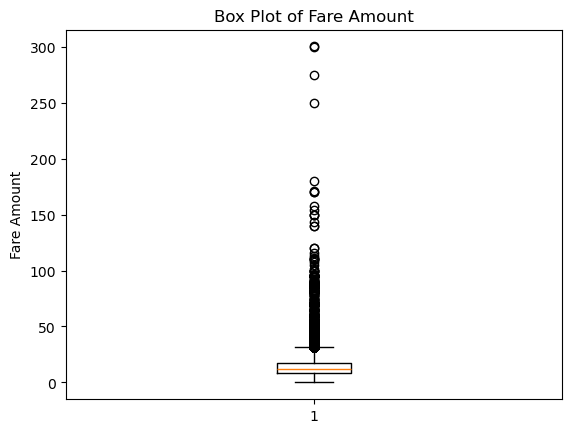

In [780]:
plt.boxplot(x=df['fare_amount'])
plt.title('Box Plot of Fare Amount')
plt.ylabel('Fare Amount')
plt.show()

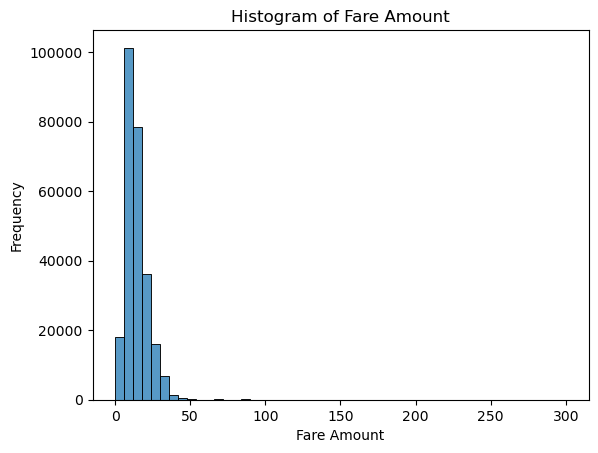

In [781]:
sns.histplot(x=df['fare_amount'], bins=50)
plt.title('Histogram of Fare Amount')
plt.xlabel('Fare Amount')
plt.ylabel('Frequency')
plt.show()

In [783]:
# Handling $0 Fares (Missing or Invalid Data)
df[(df['fare_amount'] == 0) & (df['trip_distance'] != 0)].reset_index(drop = True)  # 41 entries

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration
0,1,2023-01-17 15:23:25,2023-01-17 15:46:25,1,1.80,1,162,236,unknown,0.0,0.0,0.0,0.0,0.0,0.0,0.00,2.5,0.00,2023-01-17,15,0.383333
1,2,2023-01-30 15:47:07,2023-01-30 16:11:33,1,2.23,1,163,140,2,0.0,0.0,0.5,0.0,0.0,1.0,4.00,2.5,0.00,2023-01-30,15,0.407222
2,2,2023-11-03 15:51:42,2023-11-03 15:53:00,1,0.21,2,246,246,2,0.0,0.0,0.5,0.0,0.0,1.0,4.00,2.5,0.00,2023-11-03,15,0.021667
3,2,2023-11-05 18:13:44,2023-11-05 18:14:10,1,0.02,1,143,143,4,0.0,0.0,0.5,0.0,0.0,1.0,4.00,2.5,0.00,2023-11-05,18,0.007222
4,2,2023-11-06 08:21:14,2023-11-06 08:26:23,1,0.11,1,138,70,2,0.0,0.0,0.5,0.0,0.0,1.0,3.25,0.0,1.75,2023-11-06,8,0.085833
5,2,2023-11-06 19:30:44,2023-11-06 19:38:21,1,0.48,1,75,75,2,0.0,0.0,0.5,0.0,0.0,1.0,1.50,0.0,0.00,2023-11-06,19,0.126944
6,2,2023-11-07 15:34:50,2023-11-07 15:35:29,1,0.02,1,170,170,2,0.0,0.0,0.5,0.0,0.0,1.0,4.00,2.5,0.00,2023-11-07,15,0.010833
7,2,2023-11-22 15:44:42,2023-11-22 15:45:57,1,0.05,2,132,132,4,0.0,0.0,0.5,0.0,0.0,1.0,3.25,0.0,1.75,2023-11-22,15,0.020833
8,1,2023-12-05 09:07:28,2023-12-05 09:07:56,1,1.50,5,236,236,4,0.0,2.5,0.0,0.0,0.0,1.0,3.50,2.5,0.00,2023-12-05,9,0.007778
9,1,2023-12-19 19:25:04,2023-12-19 19:25:53,1,0.50,5,132,132,4,0.0,0.0,0.0,0.0,0.0,1.0,1.00,0.0,0.00,2023-12-19,19,0.013611


In [785]:
# Assumption: $0 fares could either represent invalid records (e.g., canceled trips) or missing data.
# Dropping these from the dataset
df = df[~((df['fare_amount'] == 0) & (df['trip_distance'] != 0))]

In [788]:
# Handling Fares Above $100 or $200
df[df['fare_amount'] > 100].reset_index(drop = True) # 28 entries

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration
0,2,2023-01-05 20:56:49,2023-01-05 21:14:33,1,2.15,5,265,265,1,275.00,0.0,0.0,55.20,0.00,1.0,331.20,0.0,0.00,2023-01-05,20,0.295556
1,2,2023-01-26 14:12:18,2023-01-26 16:49:31,3,3.97,1,162,162,1,115.70,0.0,0.5,18.00,0.00,1.0,137.70,2.5,0.00,2023-01-26,14,2.620278
2,2,2023-10-01 21:42:04,2023-10-01 22:00:06,2,1.87,5,265,265,1,300.09,0.0,0.0,0.00,0.00,1.0,301.09,0.0,0.00,2023-10-01,21,0.300556
3,2,2023-11-05 10:52:49,2023-11-05 11:00:13,2,5.49,5,134,132,1,170.00,0.0,0.0,34.20,0.00,1.0,205.20,0.0,0.00,2023-11-05,10,0.123333
4,2,2023-12-06 22:06:34,2023-12-06 22:07:27,4,0.04,5,164,164,1,170.00,0.0,0.0,0.00,0.00,1.0,173.50,2.5,0.00,2023-12-06,22,0.014722
5,2,2023-12-13 13:01:28,2023-12-13 13:03:25,1,0.12,5,66,66,1,113.00,0.0,0.0,22.80,0.00,1.0,136.80,0.0,0.00,2023-12-13,13,0.032500
6,2,2023-12-16 04:32:18,2023-12-16 04:33:05,1,0.01,5,87,87,1,110.00,0.0,0.5,25.35,12.75,1.0,152.10,2.5,0.00,2023-12-16,4,0.013056
7,2,2023-12-21 23:15:01,2023-12-21 23:15:11,1,0.05,5,265,265,1,108.00,0.0,0.0,21.80,0.00,1.0,130.80,0.0,0.00,2023-12-21,23,0.002778
8,2,2023-12-28 04:34:23,2023-12-28 04:36:10,1,0.58,5,48,246,1,180.00,0.0,0.0,10.00,12.75,1.0,206.25,2.5,0.00,2023-12-28,4,0.029722
9,2,2023-03-04 01:28:07,2023-03-04 01:32:21,1,0.84,5,249,68,1,120.00,0.0,0.0,24.70,0.00,1.0,148.20,2.5,0.00,2023-03-04,1,0.070556


In [790]:
# Assumption: Fares above $100 or $200 could be due to long-distance trips or anomalies.
# Capping fares above cap_value set to $200 
cap_value = 100  # Set cap value $100
df['fare_amount'] = df['fare_amount'].clip(upper=cap_value)  # Cap fares above $100

Tip Amount

In [793]:
df.tip_amount.describe()

count    258805.000000
mean          2.748460
std           2.306364
min           0.000000
25%           1.000000
50%           2.720000
75%           3.980000
max         150.290000
Name: tip_amount, dtype: float64

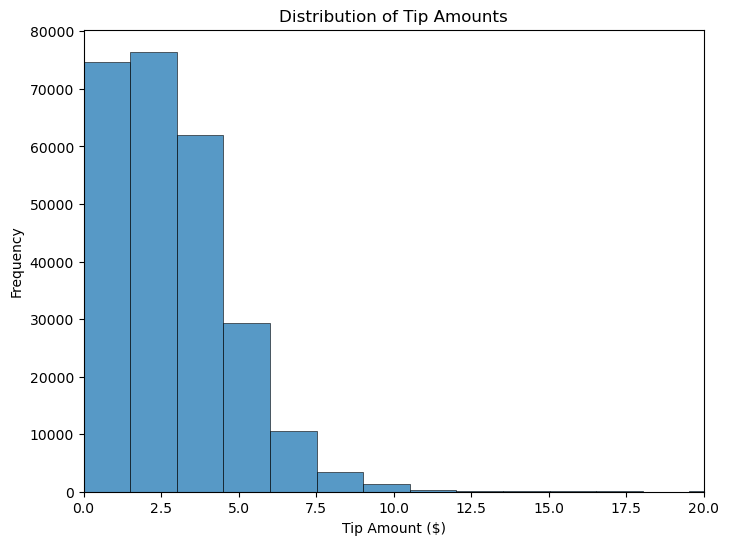

In [795]:
plt.figure(figsize=(8, 6))
sns.histplot(df['tip_amount'], bins=100)
plt.xlim(0, 20)  # Limiting x-axis to exclude extreme outliers for better visualization
plt.title('Distribution of Tip Amounts')
plt.xlabel('Tip Amount ($)')
plt.ylabel('Frequency')
plt.show()

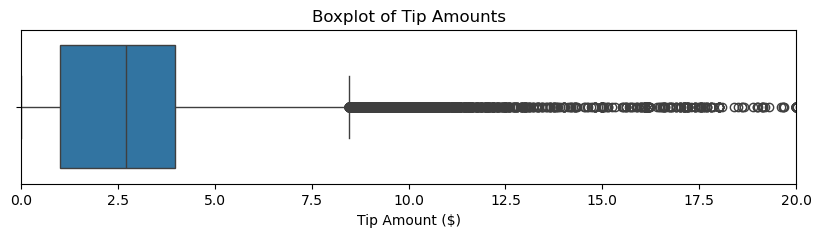

In [797]:
plt.figure(figsize=(10, 2))
sns.boxplot(x=df['tip_amount'])
plt.xlim(0, 20)  
plt.title('Boxplot of Tip Amounts')
plt.xlabel('Tip Amount ($)')
plt.show()

In [799]:
# Remving the outliers in tip_amount using IQR
Q1 = df['tip_amount'].quantile(0.25)
Q3 = df['tip_amount'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df = df[(df['tip_amount'] >= lower_bound) & (df['tip_amount'] <= upper_bound)]

Total Amount

In [802]:
df.total_amount.describe()

count    255689.000000
mean         21.276385
std           8.169914
min           1.010000
25%          15.400000
50%          19.600000
75%          25.560000
max         301.090000
Name: total_amount, dtype: float64

In [804]:
# Removing entries where total_amount > $300
df = df[df['total_amount'] <= 300]

trip duration

In [807]:
df.trip_duration.describe()

count    255688.000000
mean          0.229125
std           0.663012
min          -0.879167
25%           0.118333
50%           0.185556
75%           0.278889
max          90.183333
Name: trip_duration, dtype: float64

Insights:

- *Negative values** (min = -0.879): Impossible in a real-world context and likely due to clock sync issues, data entry errors or time zone inconsistencies

- *Extremely high max value* (90.18 hours ≈ 3.75 days): Very unlikely for a city taxi and could be due to missing dropoff timestamp filled with a wrong default or misrecorded trip duration
---

In [810]:
# Removing negative durations
df = df[df['trip_duration'] >= 0]

In [812]:
# Removing extremely long trips (e.g., over 3 hours)
df = df[df['trip_duration'] <= 3]

In [814]:
# Remvoing entries of zero hours duration from the dataset
df = df[df['trip_duration'] != 0]

In [816]:
df.trip_duration.describe()

count    255474.000000
mean          0.211650
std           0.125993
min           0.000278
25%           0.118333
50%           0.185278
75%           0.278611
max           2.603611
Name: trip_duration, dtype: float64

In [818]:
# Do any columns need standardising?

Trip Duration (hours column) converetd to hours unit

## **3** Exploratory Data Analysis
<font color = red>[90 marks]</font> <br>

In [822]:
df.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'airport_fee',
 'date',
 'pickup_hour',
 'trip_duration']

#### **3.1** General EDA: Finding Patterns and Trends
<font color = red>[40 marks]</font> <br>

**3.1.1** <font color = red>[3 marks]</font> <br>
Categorise the varaibles into Numerical or Categorical.
* `VendorID`: Categorical
* `tpep_pickup_datetime`: Categorical
* `tpep_dropoff_datetime`: Categorical
* `passenger_count`: Numerical
* `trip_distance`: Numerical
* `RatecodeID`: Categorical
* `PULocationID`: Categorical
* `DOLocationID`: Categorical
* `payment_type`: Categorical
* `pickup_hour`: Numerical
* `trip_duration`: Numerical


The following monetary parameters belong in the same category, is it categorical or numerical?


* `fare_amount`
* `extra`
* `mta_tax`
* `tip_amount`
* `tolls_amount`
* `improvement_surcharge`
* `total_amount`
* `congestion_surcharge`
* `airport_fee`

All the above monetary parameters are numerical

##### Temporal Analysis

**3.1.2** <font color = red>[5 marks]</font> <br>
Analyse the distribution of taxi pickups by hours, days of the week, and months.

In [828]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 255474 entries, 1 to 306441
Data columns (total 21 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               255474 non-null  int64         
 1   tpep_pickup_datetime   255474 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  255474 non-null  datetime64[ns]
 3   passenger_count        255474 non-null  int32         
 4   trip_distance          255474 non-null  float64       
 5   RatecodeID             255474 non-null  int32         
 6   PULocationID           255474 non-null  int64         
 7   DOLocationID           255474 non-null  int64         
 8   payment_type           255474 non-null  object        
 9   fare_amount            255474 non-null  float64       
 10  extra                  255474 non-null  float64       
 11  mta_tax                255474 non-null  float64       
 12  tip_amount             255474 non-null  float64  

In [830]:
# Find and show the hourly trends in taxi pickups

In [832]:
# Grouping by hour and count pickups
hourly_pickups = df.groupby('pickup_hour').size()
hourly_pickups

pickup_hour
0      6545
1      4663
2      3071
3      1956
4      1092
5       963
6      2847
7      6365
8      9163
9     10348
10    11228
11    12140
12    13122
13    13342
14    14191
15    14570
16    14619
17    16301
18    17488
19    15410
20    13639
21    13606
22    12335
23    26470
dtype: int64

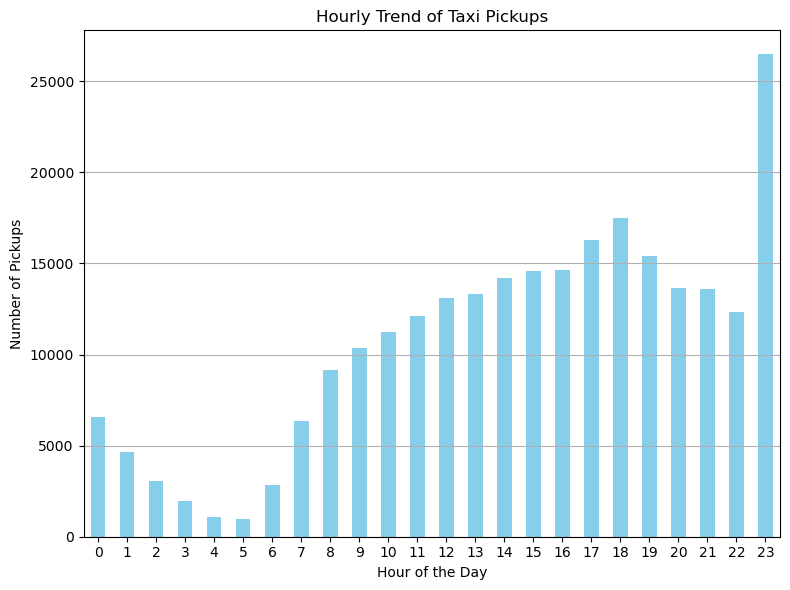

In [834]:
# Plotting the hourly pickup trend
plt.figure(figsize=(8, 6))
hourly_pickups.plot(kind='bar', color='skyblue')
plt.xlabel('Hour of the Day')
plt.ylabel('Number of Pickups')
plt.title('Hourly Trend of Taxi Pickups')
plt.xticks(rotation=0)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

In [836]:
# Find and show the daily trends in taxi pickups (days of the week)

In [838]:
# Add a day of the week column (0 = Monday, 6 = Sunday)
df['day_of_week'] = df['date'].dt.day_name()

# Group by day of the week and count pickups
pickup_counts = df['day_of_week'].value_counts().reindex([
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
])

In [840]:
pickup_counts

day_of_week
Monday       30801
Tuesday      36801
Wednesday    39945
Thursday     39970
Friday       37664
Saturday     39598
Sunday       30695
Name: count, dtype: int64

In [842]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration,day_of_week
1,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2,1.24,1,161,237,1,7.9,1.0,0.5,2.58,0.0,1.0,15.48,2.5,0.0,2023-01-01,0,0.084722,Sunday
2,2,2023-01-01 00:14:03,2023-01-01 00:24:36,3,1.44,1,237,141,2,11.4,1.0,0.5,0.00,0.0,1.0,16.40,2.5,0.0,2023-01-01,0,0.175833,Sunday
3,2,2023-01-01 00:24:30,2023-01-01 00:29:55,1,0.54,1,143,142,2,6.5,1.0,0.5,0.00,0.0,1.0,11.50,2.5,0.0,2023-01-01,0,0.090278,Sunday
6,2,2023-01-01 00:58:00,2023-01-01 01:08:31,2,1.59,1,79,164,1,11.4,1.0,0.5,3.28,0.0,1.0,19.68,2.5,0.0,2023-01-01,0,0.175278,Sunday
7,2,2023-01-01 00:16:06,2023-01-01 00:31:59,1,3.16,1,79,256,1,19.1,1.0,0.5,6.02,0.0,1.0,30.12,2.5,0.0,2023-01-01,0,0.264722,Sunday


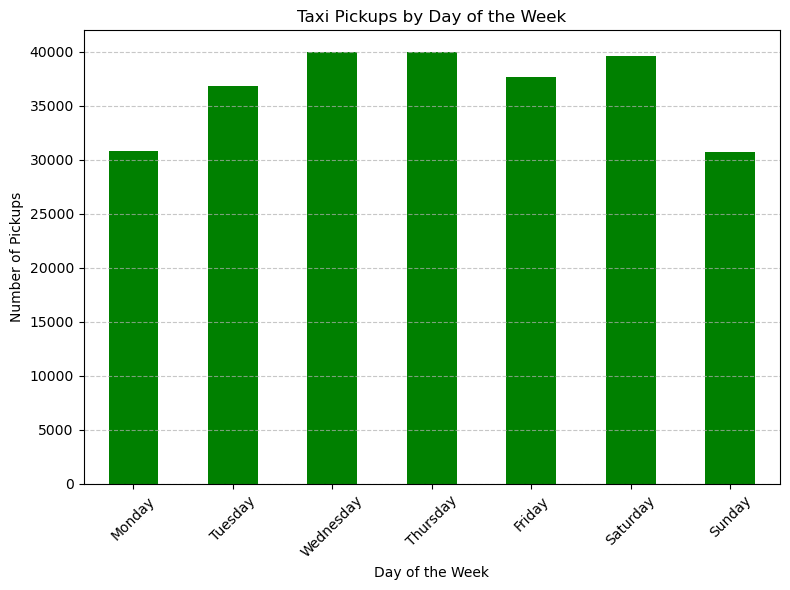

In [844]:
# Plotting the daily pickup trend
plt.figure(figsize=(8, 6))
pickup_counts.plot(kind='bar', color='green')
plt.title("Taxi Pickups by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Number of Pickups")
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [846]:
# Show the monthly trends in pickups

In [848]:
# To show the monthly trends in pickups, grouping the data by month and count the number of pickups for each month

# Extracting the month and year from the pickup datetime
df['pickup_month'] = df['tpep_pickup_datetime'].dt.to_period('M')

# Grouping by month and counting the number of pickups
monthly_pickups = df.groupby('pickup_month').size()

# Converting PeriodIndex to datetime for plotting
monthly_pickups.index = monthly_pickups.index.to_timestamp()

In [850]:
monthly_pickups

pickup_month
2023-01-01    19843
2023-02-01    19798
2023-03-01    23900
2023-04-01    22462
2023-05-01    24450
2023-06-01    22505
2023-07-01    19356
2023-08-01    18465
2023-09-01    17815
2023-10-01    23143
2023-11-01    20980
2023-12-01    22757
Freq: MS, dtype: int64

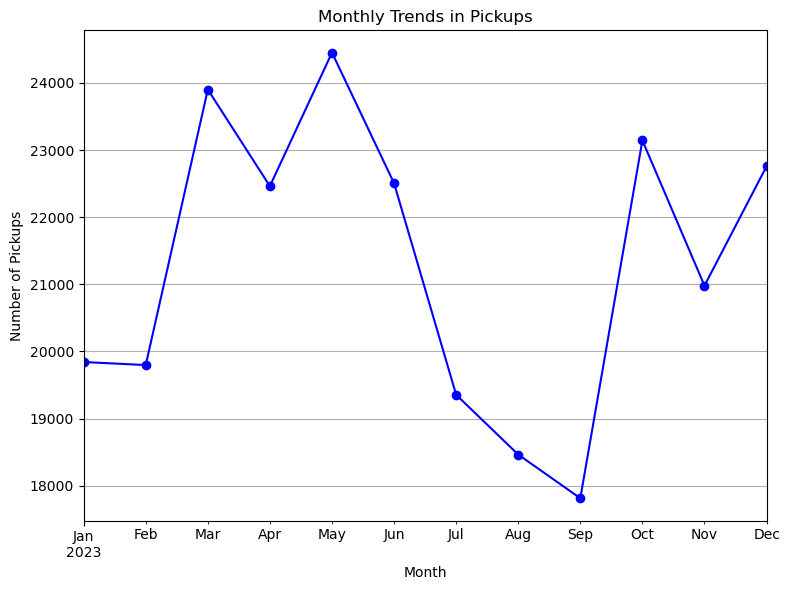

In [852]:
# Plotting the monthly pickup trend
plt.figure(figsize=(8, 6))
monthly_pickups.plot(kind='line', marker='o', color='blue')
plt.title('Monthly Trends in Pickups')
plt.xlabel('Month')
plt.ylabel('Number of Pickups')
plt.grid(True)
plt.tight_layout()
plt.show()

##### Financial Analysis

Take a look at the financial parameters like `fare_amount`, `tip_amount`, `total_amount`, and also `trip_distance`. Do these contain zero/negative values?

In [856]:
# Analyse the above parameters
(df['fare_amount'] == 0).any()

False

In [858]:
(df['fare_amount'] < 0).any()

False

In [860]:
(df['tip_amount'] == 0).any()

True

In [862]:
(df['tip_amount'] < 0).any()

False

In [864]:
(df['total_amount'] == 0).any()

False

In [866]:
(df['total_amount'] < 0).any()

False

In [868]:
(df['trip_distance'] == 0).any()

False

In [870]:
(df['trip_distance'] < 0).any()

False

There are zero values in tip_amount column

- tip_amount can be zero if the passenger did not leave a tip, if the fare was paid in cash, and tips weren't recorded, a data entry or processing issue lead to a missing or zero value.

Do you think it is beneficial to create a copy DataFrame leaving out the zero values from these?

In [874]:
df_zero_values = df[df['tip_amount'] == 0].copy()

**3.1.3** <font color = red>[2 marks]</font> <br>
Filter out the zero values from the above columns.

**Note:** The distance might be 0 in cases where pickup and drop is in the same zone. Do you think it is suitable to drop such cases of zero distance?

In [877]:
data = df[((df['trip_distance'] == 0) & (df['PULocationID'] == df['DOLocationID']))]

In [879]:
len(data)

0

In [881]:
# Create a df with non zero entries for the selected parameters.
df_non_zero = df[df['tip_amount'] > 0].copy().reset_index(drop=True)

In [883]:
df_non_zero.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200465 entries, 0 to 200464
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               200465 non-null  int64         
 1   tpep_pickup_datetime   200465 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  200465 non-null  datetime64[ns]
 3   passenger_count        200465 non-null  int32         
 4   trip_distance          200465 non-null  float64       
 5   RatecodeID             200465 non-null  int32         
 6   PULocationID           200465 non-null  int64         
 7   DOLocationID           200465 non-null  int64         
 8   payment_type           200465 non-null  object        
 9   fare_amount            200465 non-null  float64       
 10  extra                  200465 non-null  float64       
 11  mta_tax                200465 non-null  float64       
 12  tip_amount             200465 non-null  floa

**3.1.4** <font color = red>[3 marks]</font> <br>
Analyse the monthly revenue (`total_amount`) trend

In [886]:
# Group data by month and analyse monthly revenue

In [888]:
# Group by pickup_month and sum the total_amount
monthly_revenue = df_non_zero.groupby('pickup_month')['total_amount'].sum().reset_index()

# Renaming columns for clarity
monthly_revenue.columns = ['Month', 'Monthly Revenue']

# Sorting by month as its not already sorted
monthly_revenue = monthly_revenue.sort_values('Month')

# Displaying result
print(monthly_revenue)

      Month  Monthly Revenue
0   2023-01        332755.90
1   2023-02        339425.46
2   2023-03        409519.95
3   2023-04        375533.92
4   2023-05        427064.44
5   2023-06        392944.60
6   2023-07        320490.49
7   2023-08        307787.28
8   2023-09        311869.75
9   2023-10        417057.83
10  2023-11        376975.98
11  2023-12        395564.97


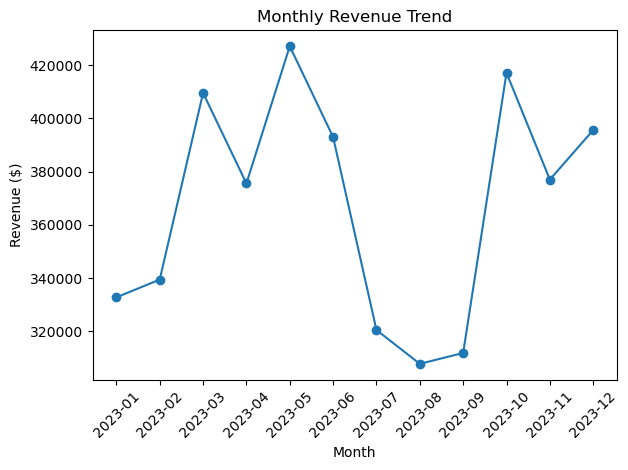

In [890]:
# Plotting monthly revenue trends
plt.plot(monthly_revenue['Month'].astype(str), monthly_revenue['Monthly Revenue'], marker='o')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue ($)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**3.1.5** <font color = red>[3 marks]</font> <br>
Show the proportion of each quarter of the year in the revenue

In [893]:
df_non_zero.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200465 entries, 0 to 200464
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               200465 non-null  int64         
 1   tpep_pickup_datetime   200465 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  200465 non-null  datetime64[ns]
 3   passenger_count        200465 non-null  int32         
 4   trip_distance          200465 non-null  float64       
 5   RatecodeID             200465 non-null  int32         
 6   PULocationID           200465 non-null  int64         
 7   DOLocationID           200465 non-null  int64         
 8   payment_type           200465 non-null  object        
 9   fare_amount            200465 non-null  float64       
 10  extra                  200465 non-null  float64       
 11  mta_tax                200465 non-null  float64       
 12  tip_amount             200465 non-null  floa

In [895]:
# Calculate proportion of each quarter

In [897]:
# Adding a Quarter Column
df_non_zero['quarter'] = df_non_zero['tpep_pickup_datetime'].dt.to_period('Q')

# Group by Quarter and Sum Revenue
# Assuming `total_amount` is the revenue:

quarterly_revenue = df_non_zero.groupby('quarter')['total_amount'].sum()

# Calculating Proportions
quarterly_proportion = quarterly_revenue / quarterly_revenue.sum()

In [899]:
quarterly_proportion

quarter
2023Q1    0.245451
2023Q2    0.271283
2023Q3    0.213331
2023Q4    0.269934
Freq: Q-DEC, Name: total_amount, dtype: float64

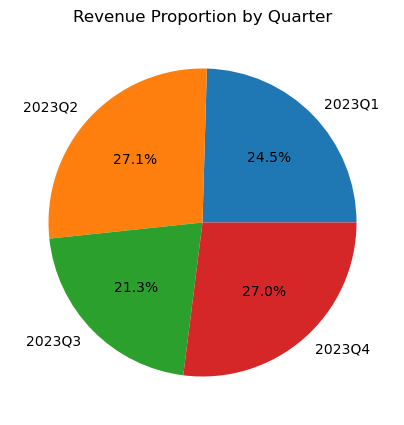

In [901]:
# Plotting quarterly revenue proportion using piechart
quarterly_proportion.plot(kind='pie', autopct='%1.1f%%', figsize=(5, 5), title='Revenue Proportion by Quarter')
plt.ylabel('')  # hide the y-label
plt.show()

**3.1.6** <font color = red>[3 marks]</font> <br>
Visualise the relationship between `trip_distance` and `fare_amount`. Also find the correlation value for these two.

**Hint:** You can leave out the trips with trip_distance = 0

In [904]:
# Show how trip fare is affected by distance

In [906]:
correlation = df_non_zero['trip_distance'].corr(df_non_zero['fare_amount'])
print(f"Correlation between fare_amount and trip_distance: {correlation:.4f}")

Correlation between fare_amount and trip_distance: 0.8810


This indicates a strong positive linear relationship between the two variables. As trip_distance increases, fare_amount tends to increase as well.

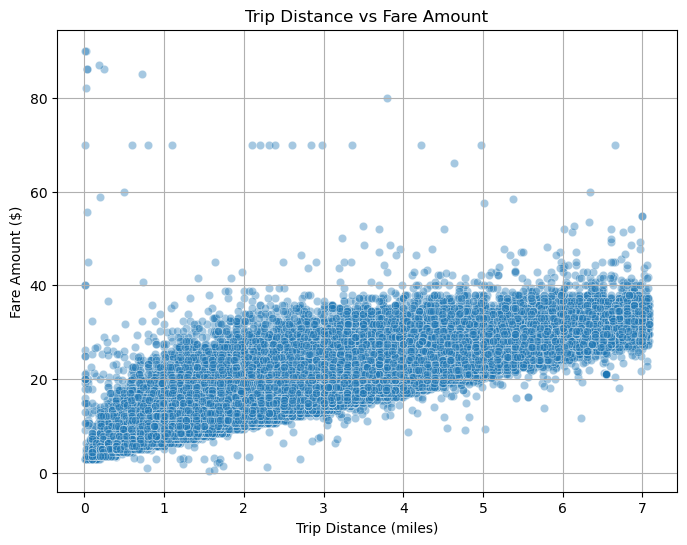

In [909]:
# Plotting trip distance vs fare amount
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_non_zero, x='trip_distance', y='fare_amount', alpha=0.4)
plt.title('Trip Distance vs Fare Amount')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Fare Amount ($)')
plt.grid(True)
plt.show()

**3.1.7** <font color = red>[5 marks]</font> <br>
Find and visualise the correlation between:
1. `fare_amount` and trip duration (pickup time to dropoff time)
2. `fare_amount` and `passenger_count`
3. `tip_amount` and `trip_distance`

In [912]:
# Show relationship between fare and trip duration
corr_1 = df_non_zero['fare_amount'].corr(df_non_zero['trip_duration'])
print(f'Fare Amount vs Trip Duration: {corr_1:.4f}')

Fare Amount vs Trip Duration: 0.9251


This indicates a strong positive relationship between the two variables. This means that as the trip duration increases, the fare amount tends to increase as well, and vice versa.

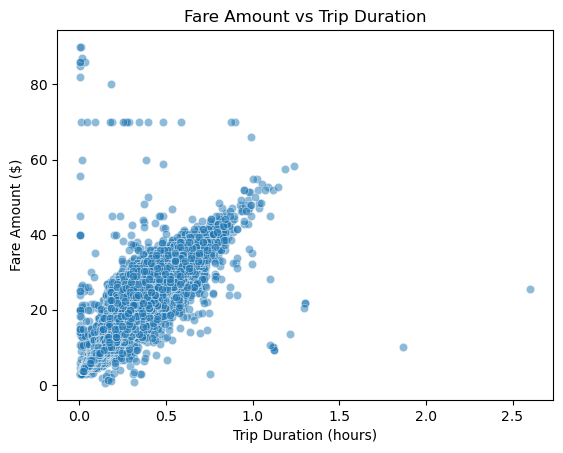

In [915]:
# Plotting - Fare Amount vs Trip Duration
sns.scatterplot(x='trip_duration', y='fare_amount', data=df_non_zero, alpha=0.5)
plt.title('Fare Amount vs Trip Duration')
plt.xlabel('Trip Duration (hours)')
plt.ylabel('Fare Amount ($)')
plt.show()

In [916]:
# Show relationship between fare and number of passengers
corr_2 = df_non_zero['fare_amount'].corr(df_non_zero['passenger_count'])
print(f'Fare Amount vs Passenger Count: {corr_2:.4f}')

Fare Amount vs Passenger Count: 0.0127


This indicates a very weak positive relationship between the two variables. Essentially, there is almost no relationship between the number of passengers and the fare amount. A value close to 0 suggests that changes in the number of passengers have little to no impact on the fare amount. I

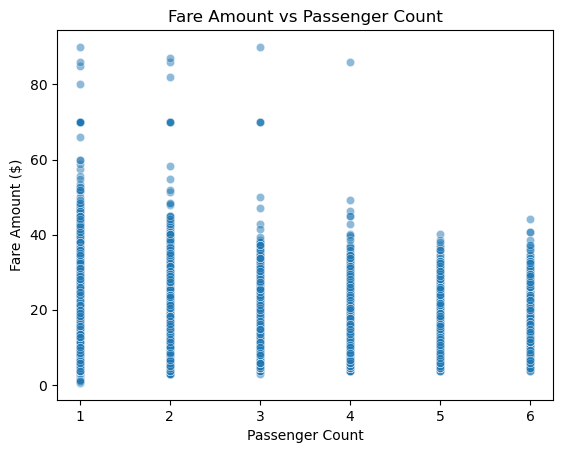

In [920]:
sns.scatterplot(x='passenger_count', y='fare_amount', data=df_non_zero, alpha=0.5)
plt.title('Fare Amount vs Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Fare Amount ($)')
plt.show()

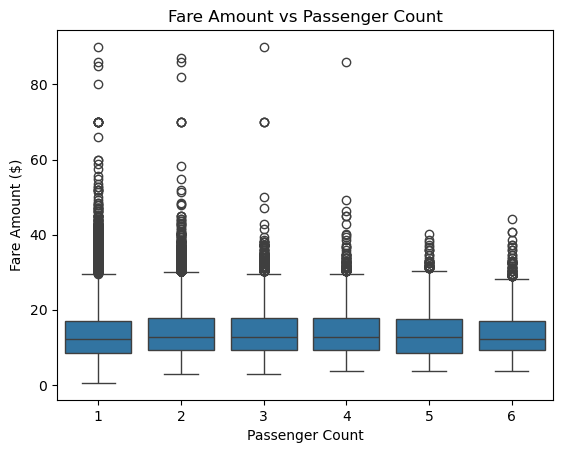

In [921]:
# Plotting - Fare Amount vs Passenger Count
sns.boxplot(x='passenger_count', y='fare_amount', data=df_non_zero)
plt.title('Fare Amount vs Passenger Count')
plt.xlabel('Passenger Count')
plt.ylabel('Fare Amount ($)')
plt.show()

In [923]:
# Show relationship between tip and trip distance
corr_3 = df_non_zero['tip_amount'].corr(df_non_zero['trip_distance'])
print(f'Tip Amount vs Trip Distance: {corr_3:.4f}')

Tip Amount vs Trip Distance: 0.6040


This indicates a moderately strong positive linear relationship. As trip distance increases, the tip amount tends to increase as well. However, the correlation isn't perfect (i.e., not close to 1.0). 

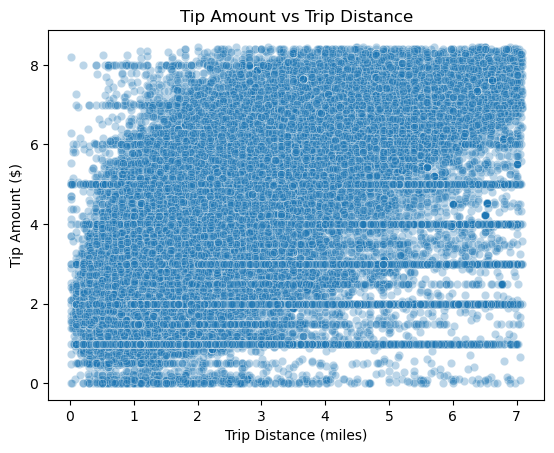

In [927]:
# Plotting - Tip Amount vs Trip Distance
sns.scatterplot(x='trip_distance', y='tip_amount', data=df_non_zero, alpha=0.3)
plt.title('Tip Amount vs Trip Distance')
plt.xlabel('Trip Distance (miles)')
plt.ylabel('Tip Amount ($)')
plt.show()

**3.1.8** <font color = red>[3 marks]</font> <br>
Analyse the distribution of different payment types (`payment_type`)

In [930]:
# Analyse the distribution of different payment types (payment_type).
payment_distribution = df_non_zero['payment_type'].value_counts()
print(payment_distribution)

payment_type
1          195745
unknown      4711
2               5
4               3
3               1
Name: count, dtype: int64


- 1= Credit card
- 2= Cash
- 3= No charge
- 4= Dispute
- unknown - missing



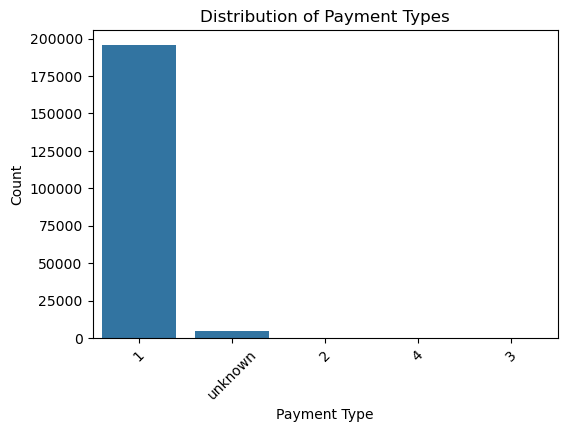

In [933]:
# Plotting the payment type distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df_non_zero, x='payment_type', order=df_non_zero['payment_type'].value_counts().index)
plt.title('Distribution of Payment Types')
plt.xlabel('Payment Type')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

##### Geographical Analysis

For this, you have to use the *taxi_zones.shp* file from the *taxi_zones* folder.

There would be multiple files inside the folder (such as *.shx, .sbx, .sbn* etc). You do not need to import/read any of the files other than the shapefile, *taxi_zones.shp*.

Do not change any folder structure - all the files need to be present inside the folder for it to work.

The folder structure should look like this:
```
Taxi Zones
|- taxi_zones.shp.xml
|- taxi_zones.prj
|- taxi_zones.sbn
|- taxi_zones.shp
|- taxi_zones.dbf
|- taxi_zones.shx
|- taxi_zones.sbx

 ```

 You only need to read the `taxi_zones.shp` file. The *shp* file will utilise the other files by itself.

We will use the *GeoPandas* library for geopgraphical analysis
```
import geopandas as gpd
```

More about geopandas and shapefiles: [About](https://geopandas.org/en/stable/about.html)


Reading the shapefile is very similar to *Pandas*. Use `gpd.read_file()` function to load the data (*taxi_zones.shp*) as a GeoDataFrame. Documentation: [Reading and Writing Files](https://geopandas.org/en/stable/docs/user_guide/io.html)

In [1549]:
# !pip install geopandas
!pip install geopandas

**3.1.9** <font color = red>[2 marks]</font> <br>
Load the shapefile and display it.

In [939]:
# import geopandas as gpd
import geopandas as gpd
shapefile_path = r'C:\Users\keert\OneDrive\Desktop\upGrad\C2 Data Toolkit\EDA\EDA Assignment\Datasets and Dictionary\taxi_zones\taxi_zones.shp'
# Read the shapefile using geopandas
zones = gpd.read_file(shapefile_path) # read the .shp file using gpd
zones.head()

,OBJECTID,Shape_Leng,Shape_Area,zone,LocationID,borough,geometry
0,1,0.116357,0.000782,Newark Airport,1,EWR,"POLYGON ((933100.918 192536.086, 933091.011 19..."
1,2,0.433470,0.004866,Jamaica Bay,2,Queens,"MULTIPOLYGON (((1033269.244 172126.008, 103343..."
2,3,0.084341,0.000314,Allerton/Pelham Gardens,3,Bronx,"POLYGON ((1026308.77 256767.698, 1026495.593 2..."
3,4,0.043567,0.000112,Alphabet City,4,Manhattan,"POLYGON ((992073.467 203714.076, 992068.667 20..."
4,5,0.092146,0.000498,Arden Heights,5,Staten Island,"POLYGON ((935843.31 144283.336, 936046.565 144..."


Now, if you look at the DataFrame created, you will see columns like: `OBJECTID`,`Shape_Leng`, `Shape_Area`, `zone`, `LocationID`, `borough`, `geometry`.
<br><br>

Now, the `locationID` here is also what we are using to mark pickup and drop zones in the trip records.

The geometric parameters like shape length, shape area and geometry are used to plot the zones on a map.

This can be easily done using the `plot()` method.

In [942]:
# print(zones.info())
zones.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   OBJECTID    263 non-null    int32   
 1   Shape_Leng  263 non-null    float64 
 2   Shape_Area  263 non-null    float64 
 3   zone        263 non-null    object  
 4   LocationID  263 non-null    int32   
 5   borough     263 non-null    object  
 6   geometry    263 non-null    geometry
dtypes: float64(2), geometry(1), int32(2), object(2)
memory usage: 12.5+ KB


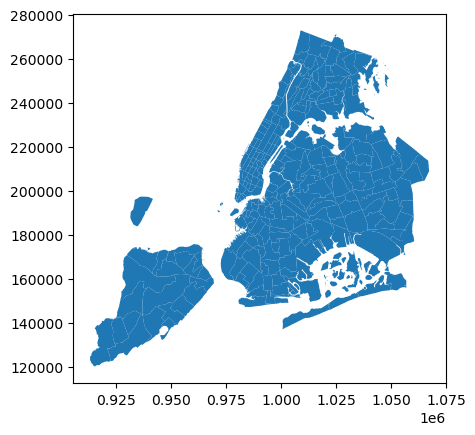

In [944]:
# zones.plot()
zones.plot()
plt.show()

Now, you have to merge the trip records and zones data using the location IDs.



In [947]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 255474 entries, 1 to 306441
Data columns (total 23 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               255474 non-null  int64         
 1   tpep_pickup_datetime   255474 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  255474 non-null  datetime64[ns]
 3   passenger_count        255474 non-null  int32         
 4   trip_distance          255474 non-null  float64       
 5   RatecodeID             255474 non-null  int32         
 6   PULocationID           255474 non-null  int64         
 7   DOLocationID           255474 non-null  int64         
 8   payment_type           255474 non-null  object        
 9   fare_amount            255474 non-null  float64       
 10  extra                  255474 non-null  float64       
 11  mta_tax                255474 non-null  float64       
 12  tip_amount             255474 non-null  float64  

**3.1.10** <font color = red>[3 marks]</font> <br>
Merge the zones data into trip data using the `locationID` and `PULocationID` columns.

In [950]:
# Merge zones and trip records using locationID and PULocationID

In [952]:
# Renaming the necessary columns to avoid collision during merge
# Create a copy of zones_gdf for pickup and dropoff
pickup_zones = zones[['LocationID', 'zone', 'borough']].rename(columns={
    'LocationID': 'PULocationID',
    'zone': 'PU_zone',
    'borough': 'PU_borough'
})

dropoff_zones = zones[['LocationID', 'zone', 'borough']].rename(columns={
    'LocationID': 'DOLocationID',
    'zone': 'DO_zone',
    'borough': 'DO_borough'
})

In [954]:
# Merging pickup zone data
df = df.merge(pickup_zones, on='PULocationID', how='left')

In [956]:
#  Merging dropoff zone data
df = df.merge(dropoff_zones, on='DOLocationID', how='left')

**3.1.11** <font color = red>[3 marks]</font> <br>
Group data by location IDs to find the total number of trips per location ID

In [959]:
# Group data by location and calculate the number of trips

In [961]:
pickup_counts = df['PULocationID'].value_counts()
dropoff_counts = df['DOLocationID'].value_counts()

total_trip_counts = pickup_counts.add(dropoff_counts, fill_value=0).reset_index()
total_trip_counts.columns = ['LocationID', 'total_trips']

In [963]:
pd.set_option('display.max_rows', 240)

In [965]:
trips_df = total_trip_counts
trips_df

,LocationID,total_trips
0,1,5.0
1,4,1458.0
2,6,4.0
3,7,818.0
4,8,4.0
5,9,1.0
6,10,262.0
7,11,2.0
8,12,264.0
9,13,3172.0


In [967]:
trips_df.sort_values(by='total_trips', ascending=False).head(10)

,LocationID,total_trips
200,237,25098.0
199,236,24057.0
133,161,23294.0
134,162,17537.0
116,142,17360.0
193,230,16584.0
142,170,16165.0
155,186,15966.0
202,239,15577.0
135,163,14595.0


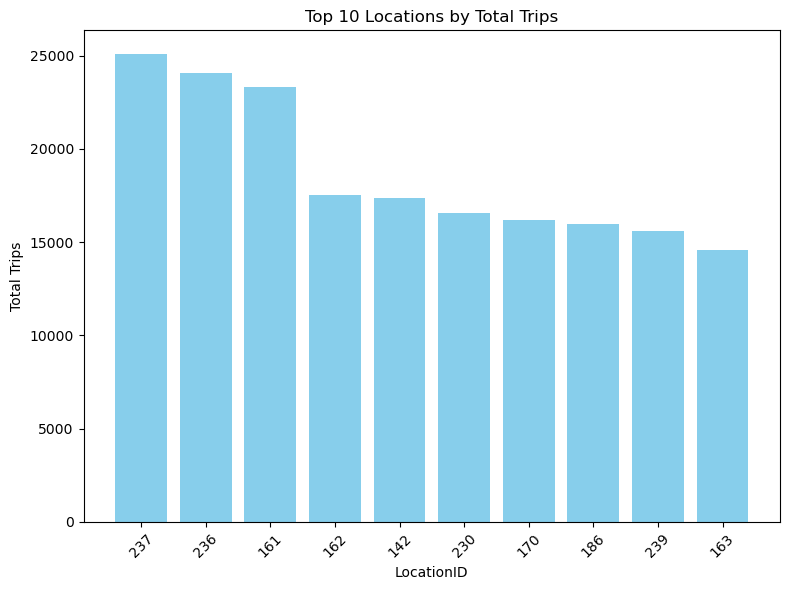

In [969]:
# Sorting and selecting top 10
top10 = trips_df.sort_values(by='total_trips', ascending=False).head(10)

# Plotting a bar plot of LocationID vs Total trips(top 10)
plt.figure(figsize=(8, 6))
plt.bar(top10['LocationID'].astype(str), top10['total_trips'], color='skyblue')
plt.xlabel('LocationID')
plt.ylabel('Total Trips')
plt.title('Top 10 Locations by Total Trips')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [971]:
location_ids = [237, 236, 161, 162, 142, 230, 170, 186, 239, 163]

# Filtering DataFrame based on LocationID to get the corresponding zone
zones[zones['LocationID'].isin(location_ids)][['LocationID', 'zone']].reset_index(drop = True)

,LocationID,zone
0,142,Lincoln Square East
1,161,Midtown Center
2,162,Midtown East
3,163,Midtown North
4,170,Murray Hill
5,186,Penn Station/Madison Sq West
6,230,Times Sq/Theatre District
7,236,Upper East Side North
8,237,Upper East Side South
9,239,Upper West Side South


**3.1.12** <font color = red>[2 marks]</font> <br>
Now, use the grouped data to add number of trips to the GeoDataFrame.

We will use this to plot a map of zones showing total trips per zone.

In [974]:
# Merge trip counts back to the zones GeoDataFrame
merged_gdf = zones.merge(trips_df, on='LocationID', how='left')

In [976]:
merged_gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   OBJECTID     263 non-null    int32   
 1   Shape_Leng   263 non-null    float64 
 2   Shape_Area   263 non-null    float64 
 3   zone         263 non-null    object  
 4   LocationID   263 non-null    int32   
 5   borough      263 non-null    object  
 6   geometry     263 non-null    geometry
 7   total_trips  226 non-null    float64 
dtypes: float64(3), geometry(1), int32(2), object(2)
memory usage: 14.5+ KB


The next step is creating a color map (choropleth map) showing zones by the number of trips taken.

Again, you can use the `zones.plot()` method for this. [Plot Method GPD](https://geopandas.org/en/stable/docs/reference/api/geopandas.GeoDataFrame.plot.html#geopandas.GeoDataFrame.plot)

But first, you need to define the figure and axis for the plot.

`fig, ax = plt.subplots(1, 1, figsize = (12, 10))`

This function creates a figure (fig) and a single subplot (ax)

---

After setting up the figure and axis, we can proceed to plot the GeoDataFrame on this axis. This is done in the next step where we use the plot method of the GeoDataFrame.

You can define the following parameters in the `zones.plot()` method:
```
column = '',
ax = ax,
legend = True,
legend_kwds = {'label': "label", 'orientation': "<horizontal/vertical>"}
```

To display the plot, use `plt.show()`.

**3.1.13** <font color = red>[3 marks]</font> <br>
Plot a color-coded map showing zone-wise trips

In [981]:
# Filling missing values with 0 
merged_gdf['total_trips'] = merged_gdf['total_trips'].fillna(0)

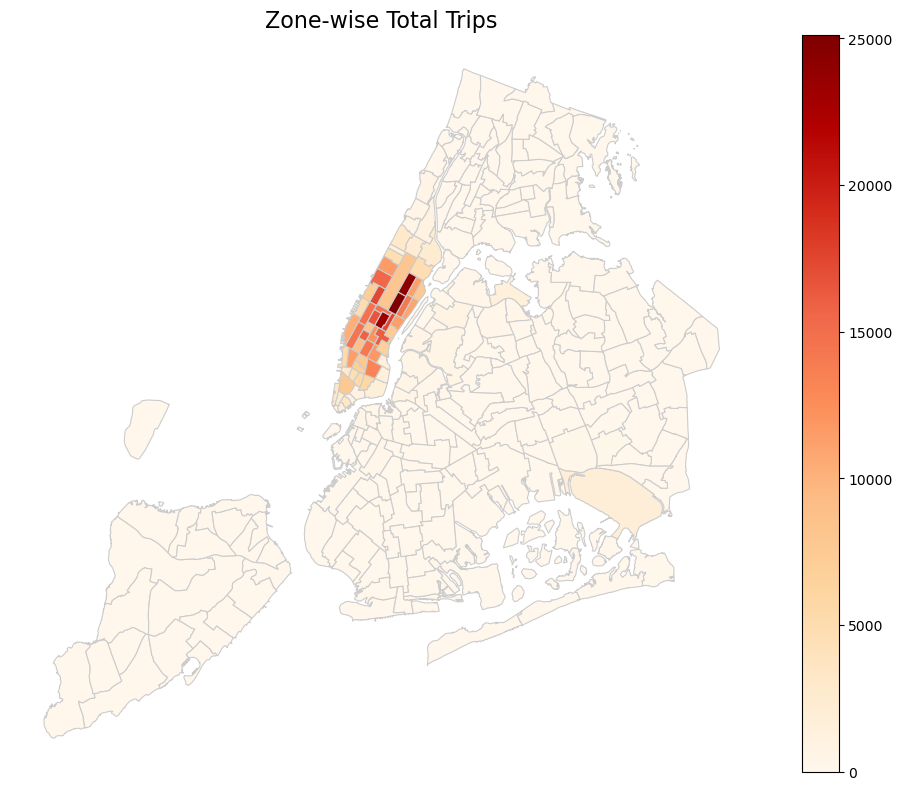

In [983]:
# Defining figure and axis
fig, ax = plt.subplots(1, 1, figsize = (10, 8))

# Plotting the map 
merged_gdf.plot(column='total_trips', cmap='OrRd', linewidth=0.8, edgecolor='0.8', legend=True, ax=ax)    # Color map (orange-red)
ax.set_title('Zone-wise Total Trips', fontsize=16)
ax.axis('off')  # Turn off axis
plt.tight_layout()
plt.show()

In [984]:
# can you try displaying the zones DF sorted by the number of trips?
sorted_zones_df = merged_gdf.sort_values(by='total_trips', ascending=False).reset_index(drop=True)
sorted_zones_df.head(10)[['zone', 'total_trips']]

,zone,total_trips
0,Upper East Side South,25098.0
1,Upper East Side North,24057.0
2,Midtown Center,23294.0
3,Midtown East,17537.0
4,Lincoln Square East,17360.0
5,Times Sq/Theatre District,16584.0
6,Murray Hill,16165.0
7,Penn Station/Madison Sq West,15966.0
8,Upper West Side South,15577.0
9,Midtown North,14595.0


Here we have completed the temporal, financial and geographical analysis on the trip records.

**Compile your findings from general analysis below:**

You can consider the following points:

* Busiest hours, days and months 
* Trends in revenue collected
* Trends in quarterly revenue
* How fare depends on trip distance, trip duration and passenger counts
* How tip amount depends on trip distance
* Busiest zones


##### Busiest hours, days and months
- Busiest hours - There is a significant spike in pickups at hour 23, followed by hours 17 and 18
- Busiest days - Wednesday and Thursday have the highest pickup counts, with 40,631 and 40,708, respectively. Saturday also sees a high count of 40,388, indicating that weekends and mid-week are the busiest days.
- Busiest months - May 2023 - 24,796, March 2023 - 24,228, October 2023 - 23,973

##### Trends in revenue collected
- The highest revenue occurred in May 2023 (425,966.05) and October 2023 (415,559.17).
- The lowest revenue occurred in August 2023 (307,189.31) and July 2023 (319,888.91).
- The revenue increases and decreases, with a notable dip around mid-year (June-July) and a recovery towards the end (October-December).

##### Trends in quarterly revenue
- There was a steady increase from Q1 to Q2.
- Q3 saw a dip compared to Q2.
- However, Q4 rebounded and returned to a level similar to Q2. Overall, the trend shows a fluctuation, but there seems to be a recovery towards the end of the year.

##### How fare depends on trip distance, trip duration and passenger counts
- A correlation of 0.9251 between Fare Amount and Trip Duration indicates a strong positive relationship between the two variables. This means that as the trip duration increases, the fare amount tends to increase as well, and vice versa.In practical terms, this suggests that longer trips are generally associated with higher fares, likely because more time on the trip results in higher costs for the service
- A correlation of 0.0127 between Fare Amount and Passenger Count indicates a very weak positive relationship between the two variables. Essentially, there is almost no relationship between the number of passengers and the fare amount. A value close to 0 suggests that changes in the number of passengers have little to no impact on the fare amount.In practical terms, this could mean that the fare is not heavily influenced by the number of passengers, which could imply that the fare is either set for the entire trip regardless of the number of passengers or is primarily influenced by other factors like distance and time
- A correlation of 0.8810 between Fare Amount and Trip Distance indicates a strong positive linear relationship. As trip distance increases, fare amount also tends to increase. However, it is not perfect (not 1.0) thereby implying that other factors (like surcharges, traffic delays, tolls, time of day) also influence the fare

##### How tip amount depends on trip distance
•	A correlation of 0.6040 between Tip Amount and Trip Distance suggests a moderately strong positive linear relationship. As trip distance increases, the tip amount tends to increase as well. However, the correlation isn't perfect (i.e., not close to 1.0). While longer trips tend to receive higher tips, the tip behaviour isn’t purely based on distance.

##### Busiest zones
The top five busiest zones based on total trips are:
- Upper East Side South – 25,282 trips
- Upper East Side North – 24,245 trips
- Midtown Center – 23,516 trips
- Midtown East – 17,688 trips
- Lincoln Square East – 17,550 trips

#### **3.2** Detailed EDA: Insights and Strategies
<font color = red>[50 marks]</font> <br>

Having performed basic analyses for finding trends and patterns, we will now move on to some detailed analysis focussed on operational efficiency, pricing strategies, and customer experience.

##### Operational Efficiency

Analyze variations by time of day and location to identify bottlenecks or inefficiencies in routes

**3.2.1** <font color = red>[3 marks]</font> <br>
Identify slow routes by calculating the average time taken by cabs to get from one zone to another at different hours of the day.

Speed on a route *X* for hour *Y* = (*distance of the route X / average trip duration for hour Y*)

In [1001]:
# Find routes which have the slowest speeds at different times of the day

In [1003]:
# 1. Filtering out rows with missing or invalid data
df_clean = df.dropna(subset=['PU_zone', 'DO_zone', 'trip_distance', 'trip_duration'])
df_clean = df_clean[(df_clean['trip_distance'] > 0) & (df_clean['trip_duration'] > 0)]

# 2. Group by route and hour
grouped = df_clean.groupby(['PU_zone', 'DO_zone', 'pickup_hour'])

# 3. Aggregating average duration and average distance
agg = grouped.agg({'trip_duration': 'mean','trip_distance': 'mean'}).reset_index()

# 4. Calculating speed (distance per minute)
agg['avg_speed'] = agg['trip_distance'] / agg['trip_duration']

# 5. Sorting by slowest routes (lowest speed)
slow_routes = agg.sort_values(by='avg_speed').reset_index(drop=True)

In [1005]:
slow_routes.head()

,PU_zone,DO_zone,pickup_hour,trip_duration,trip_distance,avg_speed
0,Inwood Hill Park,Inwood Hill Park,7,0.173333,0.02,0.115385
1,TriBeCa/Civic Center,West Concourse,15,0.979167,0.14,0.142979
2,Midtown Center,JFK Airport,20,1.039167,0.20,0.192462
3,LaGuardia Airport,Times Sq/Theatre District,15,1.021944,0.25,0.244632
4,Flatbush/Ditmas Park,Flatbush/Ditmas Park,2,0.165000,0.05,0.303030


How does identifying high-traffic, high-demand routes help us?

Identifying **high-traffic, high-demand routes** in a taxi records dataset provides several valuable insights and operational benefits, particularly in the context of urban planning, business strategy, and transportation efficiency. Here's how it helps:

###### 1. **Optimize Taxi Allocation**

* Taxis can be strategically positioned near high-demand routes to reduce wait times and maximize trip frequency.
* Minimizes idle time and fuel costs by avoiding low-demand zones.

###### 2. **Increase Revenue**

* Focusing on high-demand routes helps drivers and companies increase the number of trips per shift thereby leading to higher revenue.

###### 3. **Urban Traffic Management**

* Authorities can plan infrastructure improvements, such as expanding roads or improving public transport, in high-traffic areas to reduce congestion.

###### 4. **Identify Service Gaps**

* By understanding which areas are underserved despite being high-demand, taxi services can expand coverage or introduce shuttle services.

###### 5. **Improve Customer Satisfaction**

* Reduced waiting times and better coverage lead to higher customer satisfaction.

---

**3.2.2** <font color = red>[3 marks]</font> <br>
Calculate the number of trips at each hour of the day and visualise them. Find the busiest hour and show the number of trips for that hour.

In [1010]:
# Visualise the number of trips per hour and find the busiest hour

In [1012]:
# 1. Group by 'pickup_hour' and count trips
hourly_trip_counts = df.groupby('pickup_hour').size()

# 2. Find the busiest hour
busiest_hour = hourly_trip_counts.idxmax()
max_trips = hourly_trip_counts.max()

In [1014]:
busiest_hour

23

In [1016]:
max_trips

26494

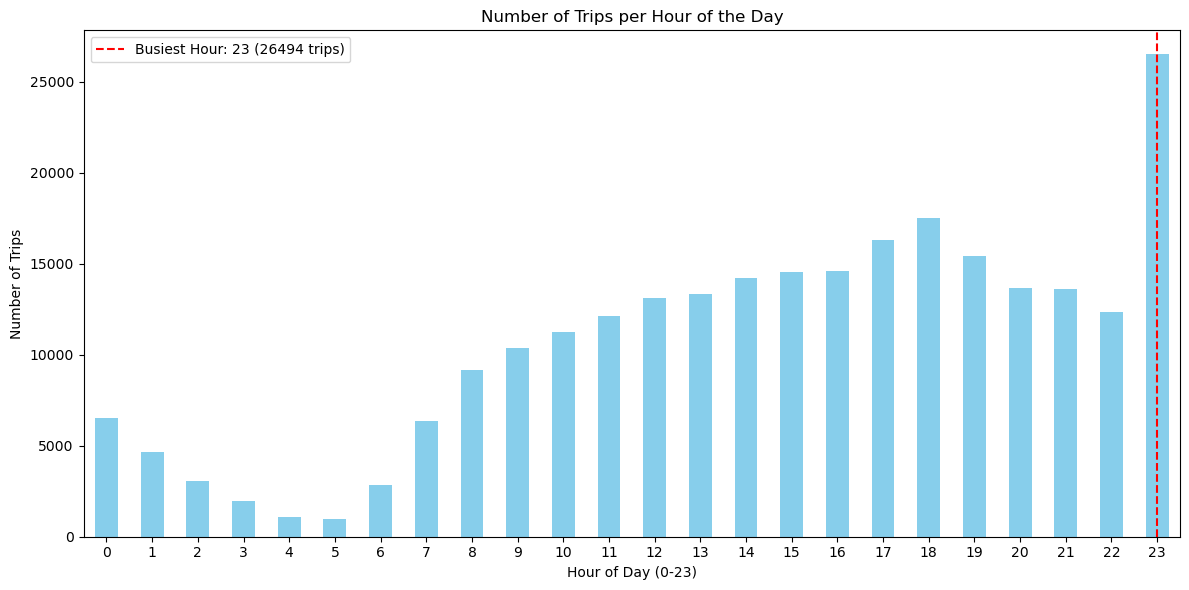

In [1018]:
# Plotting the trips per hour
plt.figure(figsize=(12, 6))
hourly_trip_counts.plot(kind='bar', color='skyblue')
plt.title('Number of Trips per Hour of the Day')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Number of Trips')
plt.xticks(rotation=0)
plt.axvline(x=busiest_hour, color='red', linestyle='--', label=f'Busiest Hour: {busiest_hour} ({max_trips} trips)')
plt.legend()
plt.tight_layout()
plt.show()

Remember, we took a fraction of trips. To find the actual number, you have to scale the number up by the sampling ratio.

**3.2.3** <font color = red>[2 mark]</font> <br>
Find the actual number of trips in the five busiest hours

In [1022]:
# Scale up the number of trips
sample_fraction = 0.0075
scaling_factor = 1 / sample_fraction  # ≈ 133.33
# Fill in the value of your sampling fraction and use that to scale up the numbers
# Scale the hourly trip counts
scaled_hourly_trip_counts = df.groupby('pickup_hour').size() * scaling_factor

# Find busiest hour
busiest_hour = scaled_hourly_trip_counts.idxmax()
max_trips = int(scaled_hourly_trip_counts.max())

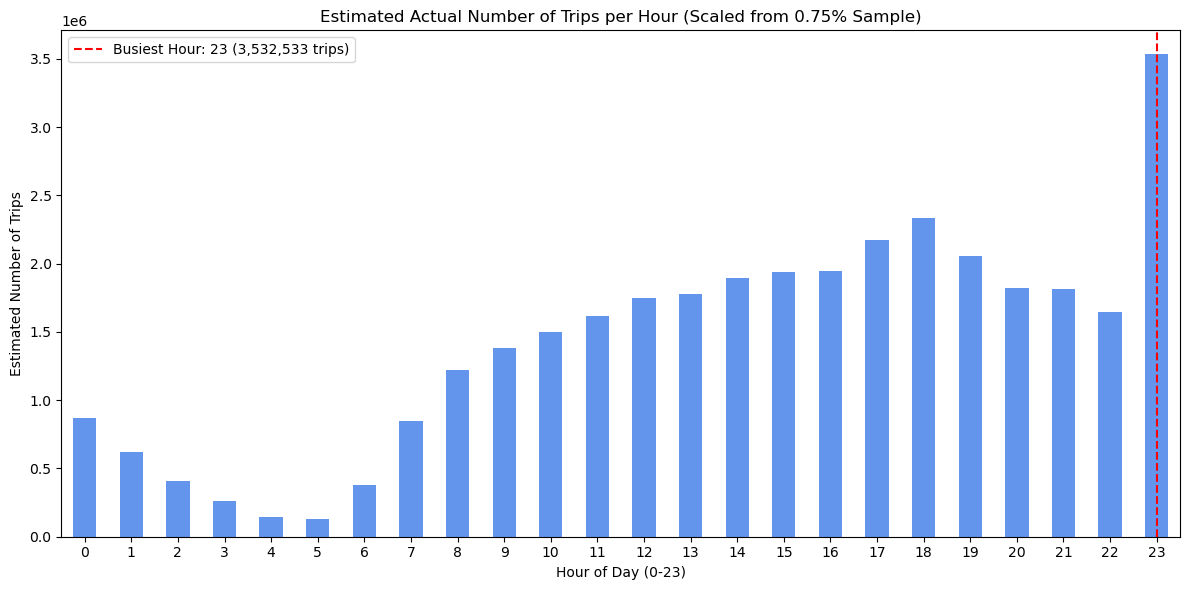

In [1024]:
# Plotting Scaled Hourly Trio Counts
plt.figure(figsize=(12, 6))
scaled_hourly_trip_counts.plot(kind='bar', color='cornflowerblue')
plt.title('Estimated Actual Number of Trips per Hour (Scaled from 0.75% Sample)')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Estimated Number of Trips')
plt.xticks(rotation=0)
plt.axvline(x=busiest_hour, color='red', linestyle='--', label=f'Busiest Hour: {busiest_hour} ({max_trips:,} trips)')
plt.legend()
plt.tight_layout()
plt.show()

In [1026]:
top_5_busiest = scaled_hourly_trip_counts.sort_values(ascending=False).head(5)
# Display result
print("Top 5 Busiest Hours (Estimated Actual Trips):")
print(top_5_busiest.astype(int))

Top 5 Busiest Hours (Estimated Actual Trips):
pickup_hour
23    3532533
18    2331866
17    2173866
19    2054800
16    1949200
dtype: int32


**3.2.4** <font color = red>[3 marks]</font> <br>
Compare hourly traffic pattern on weekdays. Also compare for weekend.

In [1029]:
# Compare traffic trends for the week days and weekends

In [1031]:
# Creating a new column to distinguish weekday/weekend
df['day_type'] = df['tpep_pickup_datetime'].dt.dayofweek.apply(lambda x: 'Weekend' if x >= 5 else 'Weekday')

In [1033]:
# Group by hour and day_type
hourly_pattern = df.groupby(['pickup_hour', 'day_type']).size().reset_index(name='trip_count')

In [1035]:
# Pivot for comparison
pivot_table = hourly_pattern.pivot(index='pickup_hour', columns='day_type', values='trip_count').fillna(0)

In [1037]:
pivot_table

day_type,Weekday,Weekend
pickup_hour,,
0,3070,3477
1,1624,3039
2,887,2184
3,524,1434
4,409,683
5,741,222
6,2436,412
7,5653,713
8,7940,1226


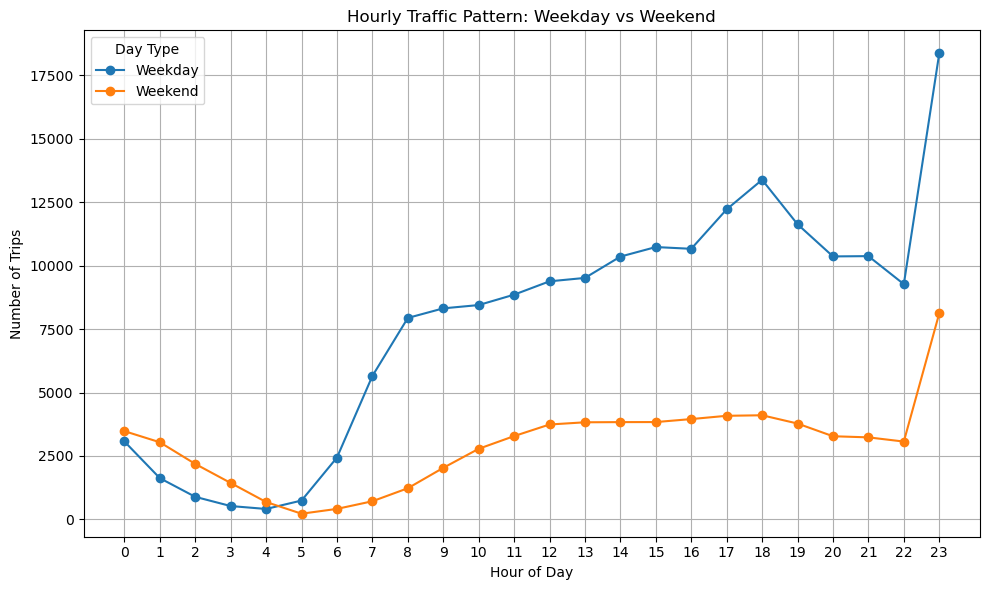

In [1039]:
# Plotting for comparing weekday vs weekend
pivot_table.plot(kind='line', figsize=(10,6), marker='o')
plt.title('Hourly Traffic Pattern: Weekday vs Weekend')
plt.xlabel('Hour of Day')
plt.ylabel('Number of Trips')
plt.grid(True)
plt.xticks(range(0, 24))
plt.legend(title='Day Type')
plt.tight_layout()
plt.show()

What can you infer from the above patterns? How will finding busy and quiet hours for each day help us?

Weekday Trends:
- Early morning (6 - 9 AM) and evening (4 -7 PM) show strong commuter peaks.
- Peak hour: 23 (11 PM) is quite high, likely due to nightlife or shift workers.
- 
Weekend Trends:
- Late morning to evening (10 AM - 6 PM) shows higher activity.
- Early hours (1- 4 AM) are significantly higher than weekdays which is consistent with leisure/nightlife activity.
- 
Overall Patterns:
- Weekdays show a more structured commuting pattern.
- Weekends have flatter midday activity and strong late-night traffic, suggesting recreational travel.
  
---

**3.2.5** <font color = red>[3 marks]</font> <br>
Identify top 10 zones with high hourly pickups. Do the same for hourly dropoffs. Show pickup and dropoff trends in these zones.

In [1044]:
# Find top 10 pickup and dropoff zones

In [1046]:
# Top 10 Zones with High Hourly Pickups

# Group by pickup zone and hour
pickup_counts = df.groupby(['PU_zone', 'pickup_hour']).size().reset_index(name='pickup_count')

# Sum pickups per zone
total_pickups = pickup_counts.groupby('PU_zone')['pickup_count'].sum().reset_index()

# Top 10 zones by total hourly pickups
top_10_pu_zones = total_pickups.sort_values(by='pickup_count', ascending=False).head(10)
top_10_pu_zone_names = top_10_pu_zones['PU_zone'].tolist()
top_10_pu_zone_names

['Upper East Side South',
 'Midtown Center',
 'Upper East Side North',
 'Midtown East',
 'Penn Station/Madison Sq West',
 'Lincoln Square East',
 'Times Sq/Theatre District',
 'Murray Hill',
 'Clinton East',
 'Upper West Side South']

In [1048]:
# Top 10 Zones with High Hourly Dropoffs

# Group by dropoff zone and pickup hour
dropoff_counts = df.groupby(['DO_zone', 'pickup_hour']).size().reset_index(name='dropoff_count')

# Sum dropoffs per zone
total_dropoffs = dropoff_counts.groupby('DO_zone')['dropoff_count'].sum().reset_index()

# Top 10 zones by total hourly dropoffs
top_10_do_zones = total_dropoffs.sort_values(by='dropoff_count', ascending=False).head(10)
top_10_do_zone_names = top_10_do_zones['DO_zone'].tolist()
top_10_do_zone_names

['Upper East Side North',
 'Upper East Side South',
 'Midtown Center',
 'Murray Hill',
 'Lincoln Square East',
 'Upper West Side South',
 'Midtown East',
 'Times Sq/Theatre District',
 'Lenox Hill West',
 'East Chelsea']

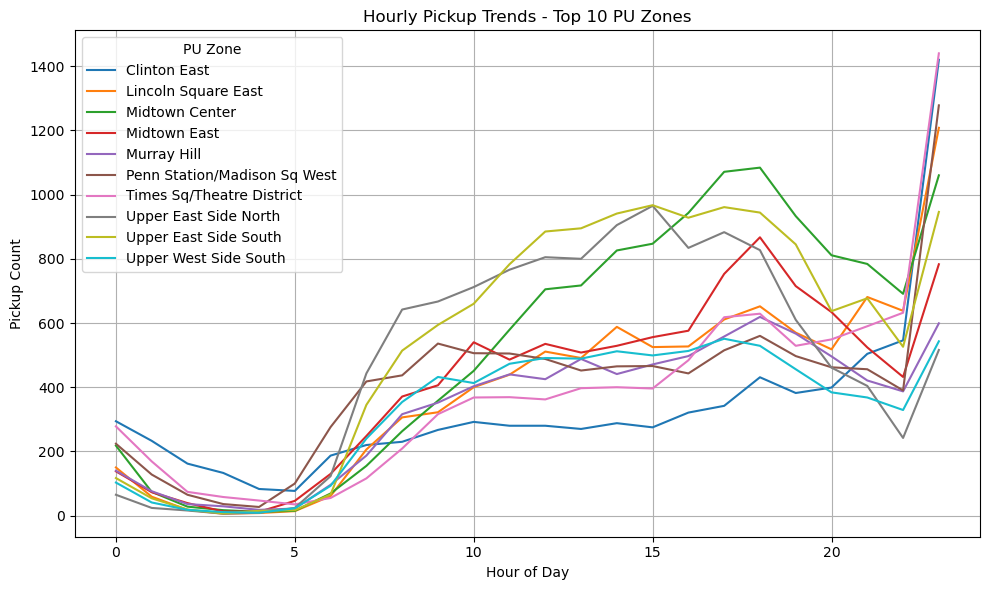

In [1050]:
# Filter pickup trends for top zones
pickup_trends = df[df['PU_zone'].isin(top_10_pu_zone_names)]
pickup_trends_grouped = pickup_trends.groupby(['PU_zone', 'pickup_hour']).size().reset_index(name='count')

# Plotting pickup trends
plt.figure(figsize=(10, 6))
sns.lineplot(data=pickup_trends_grouped, x='pickup_hour', y='count', hue='PU_zone')
plt.title('Hourly Pickup Trends - Top 10 PU Zones')
plt.xlabel('Hour of Day')
plt.ylabel('Pickup Count')
plt.legend(title='PU Zone')
plt.grid(True)
plt.tight_layout()
plt.show()

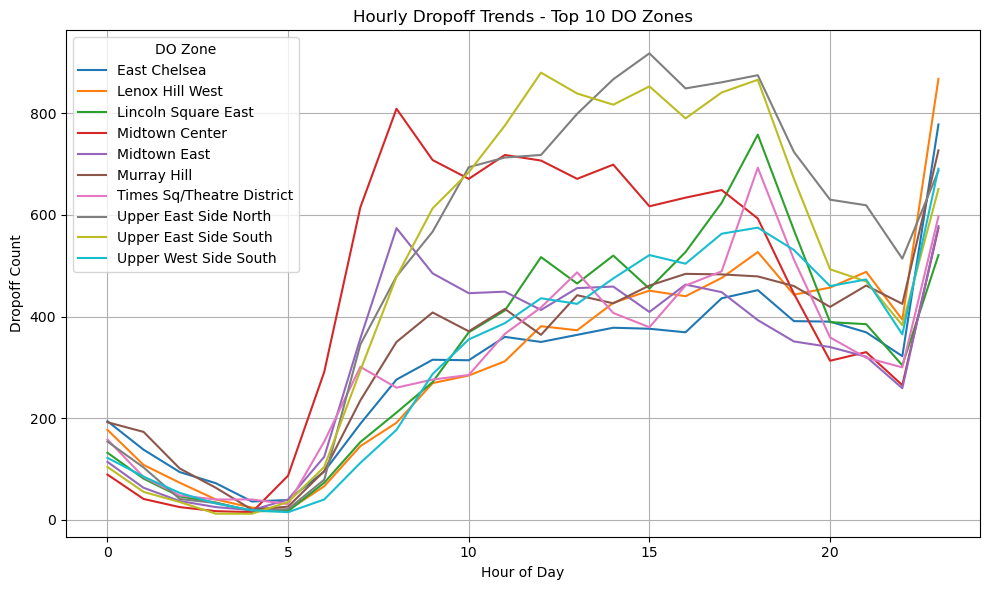

In [1052]:
# Filter dropoff trends for top zones
dropoff_trends = df[df['DO_zone'].isin(top_10_do_zone_names)]
dropoff_trends_grouped = dropoff_trends.groupby(['DO_zone', 'pickup_hour']).size().reset_index(name='count')

# Plot dropoff trends
plt.figure(figsize=(10, 6))
sns.lineplot(data=dropoff_trends_grouped, x='pickup_hour', y='count', hue='DO_zone')
plt.title('Hourly Dropoff Trends - Top 10 DO Zones')
plt.xlabel('Hour of Day')
plt.ylabel('Dropoff Count')
plt.legend(title='DO Zone')
plt.grid(True)
plt.tight_layout()
plt.show()

**3.2.6** <font color = red>[3 marks]</font> <br>
Find the ratio of pickups and dropoffs in each zone. Display the 10 highest (pickup/drop) and 10 lowest (pickup/drop) ratios.

In [1055]:
# Find the top 10 and bottom 10 pickup/dropoff ratios

In [1057]:
# Count pickups per zone
pickup_counts = df['PU_zone'].value_counts()

# Count dropoffs per zone
dropoff_counts = df['DO_zone'].value_counts()

# Combine counts into a DataFrame
zone_counts = pd.DataFrame({
    'pickup_count': pickup_counts,
    'dropoff_count': dropoff_counts
}).fillna(0)  # Fill NaNs with 0 for zones that are only pickups or only dropoffs

# Calculate pickup/dropoff ratio
zone_counts['pickup_dropoff_ratio'] = zone_counts['pickup_count'] / zone_counts['dropoff_count'].replace(0, float('nan'))

# Sort and get top 10 highest ratios
top_10_highest = zone_counts.sort_values(by='pickup_dropoff_ratio', ascending=False).head(10)

# Sort and get bottom 10 lowest ratios
bottom_10_lowest = zone_counts.sort_values(by='pickup_dropoff_ratio', ascending=True).head(10)

In [1059]:
# Displaying the result
print("Top 10 highest pickup/dropoff ratios:")
top_10_highest[['pickup_count', 'dropoff_count', 'pickup_dropoff_ratio']]

Top 10 highest pickup/dropoff ratios:


,pickup_count,dropoff_count,pickup_dropoff_ratio
LaGuardia Airport,1309.0,180.0,7.272222
JFK Airport,1607.0,304.0,5.286184
Parkchester,5.0,1.0,5.000000
Crotona Park East,4.0,1.0,4.000000
East Elmhurst,252.0,71.0,3.549296
Oakland Gardens,2.0,1.0,2.000000
Manhattan Beach,2.0,1.0,2.000000
Penn Station/Madison Sq West,9730.0,6236.0,1.560295
Greenwich Village South,4126.0,2749.0,1.500909
Central Park,4701.0,3297.0,1.425842


In [1061]:
print("\nTop 10 lowest pickup/dropoff ratios:")
bottom_10_lowest[['pickup_count', 'dropoff_count', 'pickup_dropoff_ratio']]


Top 10 lowest pickup/dropoff ratios:


,pickup_count,dropoff_count,pickup_dropoff_ratio
Saint George/New Brighton,0.0,1.0,0.0
Laurelton,0.0,31.0,0.0
Cambria Heights,0.0,18.0,0.0
East Flushing,0.0,7.0,0.0
Hunts Point,0.0,4.0,0.0
Homecrest,0.0,2.0,0.0
Hollis,0.0,4.0,0.0
Highbridge Park,0.0,4.0,0.0
Highbridge,0.0,10.0,0.0
Brownsville,0.0,3.0,0.0


**3.2.7** <font color = red>[3 marks]</font> <br>
Identify zones with high pickup and dropoff traffic during night hours (11PM to 5AM)

In [1064]:
# During night hours (11pm to 5am) find the top 10 pickup and dropoff zones
# Note that the top zones should be of night hours and not the overall top zones

In [1066]:
# Convert 'tpep_pickup_datetime' and 'tpep_dropoff_datetime' to datetime if they are not already
df['tpep_pickup_datetime'] = pd.to_datetime(df['tpep_pickup_datetime'])
df['tpep_dropoff_datetime'] = pd.to_datetime(df['tpep_dropoff_datetime'])

# Filter data for night hours (11 PM to 5 AM)
df['pickup_hour'] = df['tpep_pickup_datetime'].dt.hour
night_hours_df = df[(df['pickup_hour'] >= 23) | (df['pickup_hour'] <= 5)]

# Group by PU_zone and DO_zone and count the occurrences
pickup_counts = night_hours_df.groupby('PU_zone').size().reset_index(name='pickup_count')
dropoff_counts = night_hours_df.groupby('DO_zone').size().reset_index(name='dropoff_count')

# Merge pickup and dropoff counts
zone_traffic = pd.merge(pickup_counts, dropoff_counts, left_on='PU_zone', right_on='DO_zone', how='outer')

# Sort by pickup or dropoff counts to find the zones with the highest traffic
zone_traffic_sorted = zone_traffic.sort_values(by=['pickup_count', 'dropoff_count'], ascending=False)

# Display the zones with the highest traffic during night hours
zone_traffic_sorted.head(10).reset_index(drop=True) # Display the top 10 zones with highest traffic

,PU_zone,pickup_count,DO_zone,dropoff_count
0,East Village,3175.0,East Village,1834.0
1,West Village,2544.0,West Village,1121.0
2,Clinton East,2402.0,Clinton East,1353.0
3,Times Sq/Theatre District,2101.0,Times Sq/Theatre District,998.0
4,Greenwich Village South,1863.0,Greenwich Village South,559.0
5,Penn Station/Madison Sq West,1858.0,Penn Station/Madison Sq West,898.0
6,Lower East Side,1790.0,Lower East Side,955.0
7,Lincoln Square East,1463.0,Lincoln Square East,848.0
8,Midtown Center,1424.0,Midtown Center,848.0
9,Midtown South,1345.0,Midtown South,930.0


Now, let us find the revenue share for the night time hours and the day time hours. After this, we will move to deciding a pricing strategy.

**3.2.8** <font color = red>[2 marks]</font> <br>
Find the revenue share for nighttime and daytime hours.

In [1069]:
# Filter for night hours (11 PM to 5 AM)

In [1071]:
# Define day and night hours
# Let's say daytime is from 5 AM (inclusive) to 11 PM (exclusive), and nighttime is the rest
df['time_period'] = df['pickup_hour'].apply(lambda x: 'day' if 5 <= x < 23 else 'night')

# Group by time period and sum the total_amount (revenue)
revenue_by_period = df.groupby('time_period')['total_amount'].sum()

# Calculate total revenue
total_revenue = revenue_by_period.sum()

# Calculate share for day and night
revenue_share = (revenue_by_period / total_revenue) * 100

# Display the result
revenue_share

time_period
day      82.500458
night    17.499542
Name: total_amount, dtype: float64

Revenue share for night hours( 11 PM to 5 AM) is 17.83 %

##### Pricing Strategy

**3.2.9** <font color = red>[2 marks]</font> <br>
For the different passenger counts, find the average fare per mile per passenger.

For instance, suppose the average fare per mile for trips with 3 passengers is 3 USD/mile, then the fare per mile per passenger will be 1 USD/mile.

In [1076]:
# Analyse the fare per mile per passenger for different passenger counts

In [1078]:
# Filter out rows with zero or missing distance or passenger count
df_filtered = df[(df['trip_distance'] > 0) & (df['passenger_count'] > 0)]

# Calculate fare per mile per passenger
df_filtered['fare_per_mile_per_passenger_in_USD'] = (
    df_filtered['fare_amount'] / (df_filtered['trip_distance'] * df_filtered['passenger_count'])
)

# Group by passenger count and compute average
avg_fare = df_filtered.groupby('passenger_count')['fare_per_mile_per_passenger_in_USD'].mean().reset_index()
avg_fare

,passenger_count,fare_per_mile_per_passenger_in_USD
0,1,11.605318
1,2,5.711694
2,3,4.119702
3,4,4.026132
4,5,1.653842
5,6,1.329573


**3.2.10** <font color = red>[3 marks]</font> <br>
Find the average fare per mile by hours of the day and by days of the week

In [1081]:
# Compare the average fare per mile for different days and for different times of the day

In [1083]:
# Create a new column for fare per mile
# df = df[df['trip_distance'] > 0] # removing cases where trip distance is 0
df['fare_per_mile'] = df['fare_amount'] / df['trip_distance']
# Group by day of the week
avg_fare_day = df.groupby('day_of_week')['fare_per_mile'].mean().sort_index()
# Group by time period of the day
avg_fare_time = df.groupby('time_period')['fare_per_mile'].mean().sort_index()
# Group by both day and time
avg_fare_day_time = df.groupby(['day_of_week', 'time_period'])['fare_per_mile'].mean().unstack() # This reshapes the resulting Series into a DataFrame (pivot style):

In [1085]:
avg_fare_day_time

time_period,day,night
day_of_week,,
Friday,9.938189,8.447647
Monday,10.772960,10.909459
Saturday,10.740945,9.360906
Sunday,10.829125,38.467629
Thursday,11.525970,9.130775
Tuesday,10.511762,13.611541
Wednesday,12.177256,8.250916


In [1087]:
fare_by_day_time = df.groupby(['day_of_week', 'time_period'])['fare_per_mile'].mean().reset_index()
fare_pivot = fare_by_day_time.pivot(index='day_of_week', columns='time_period', values='fare_per_mile')

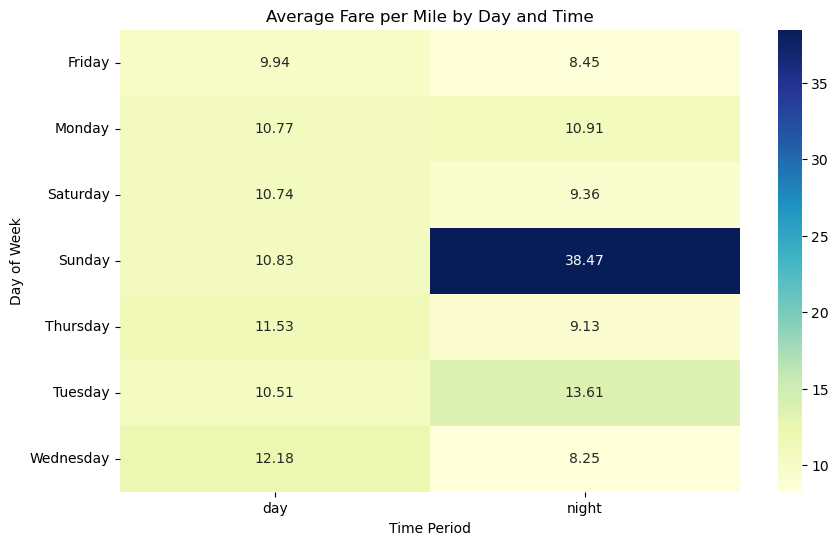

In [1089]:
plt.figure(figsize=(10, 6))
sns.heatmap(fare_pivot, annot=True, cmap='YlGnBu', fmt='.2f')
plt.title('Average Fare per Mile by Day and Time')
plt.xlabel('Time Period')
plt.ylabel('Day of Week')
plt.show()

**3.2.11** <font color = red>[3 marks]</font> <br>
Analyse the average fare per mile for the different vendors for different hours of the day

In [1092]:
# Compare fare per mile for different vendors
vendor_fare_per_mile = df.groupby('VendorID')['fare_per_mile'].mean().reset_index()
vendor_fare_per_mile = vendor_fare_per_mile.sort_values(by='fare_per_mile', ascending=True)
vendor_fare_per_mile

,VendorID,fare_per_mile
2,6,6.426728
0,1,8.327199
1,2,12.794881


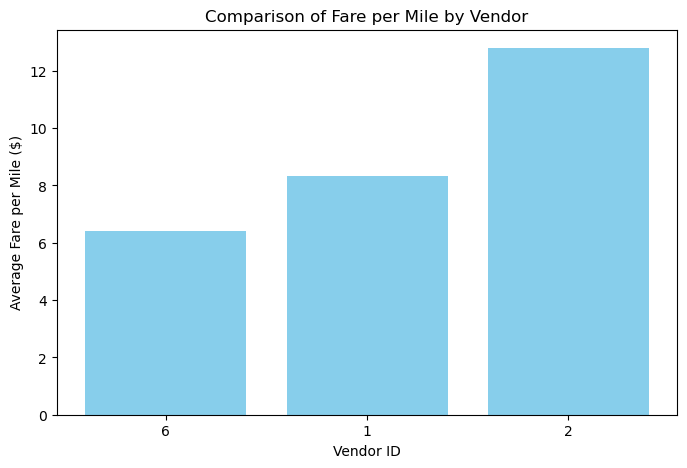

In [1094]:
# Plotting for compariosn
plt.figure(figsize=(8, 5))
plt.bar(vendor_fare_per_mile['VendorID'].astype(str), vendor_fare_per_mile['fare_per_mile'], color='skyblue')
plt.xlabel('Vendor ID')
plt.ylabel('Average Fare per Mile ($)')
plt.title('Comparison of Fare per Mile by Vendor')
plt.show()

**3.2.12** <font color = red>[5 marks]</font> <br>
Compare the fare rates of the different vendors in a tiered fashion. Analyse the average fare per mile for distances upto 2 miles. Analyse the fare per mile for distances from 2 to 5 miles. And then for distances more than 5 miles.


In [1097]:
# Defining distance tiers

Group the data into 3 tiers:
- Short trips: ≤ 2 miles
- Medium trips: > 2 and ≤ 5 miles
- Long trips: > 5 miles

In [1107]:
# Creating distance tier
def get_distance_tier(dist):
    if dist <= 2:
        return 'Short (<=2 miles)'
    elif dist <= 5:
        return 'Medium (2-5 miles)'
    else:
        return 'Long (>5 miles)'

df['distance_tier'] = df['trip_distance'].apply(get_distance_tier)

# Group by VendorID and Distance Tier to get average fare_per_mile
fare_summary = (
    df.groupby(['distance_tier', 'VendorID'])['fare_per_mile']
    .mean()
    .reset_index()
)

# Pivot for side-by-side comparison
fare_pivot = fare_summary.pivot(index='distance_tier', columns='VendorID', values='fare_per_mile')

# Renaming columns for clarity 
fare_pivot.columns = [f'Vendor {int(c)}' for c in fare_pivot.columns]

# Display the result
fare_pivot

,Vendor 1,Vendor 2,Vendor 6
distance_tier,,,
Long (>5 miles),4.912931,5.012207,5.321479
Medium (2-5 miles),6.247271,6.445276,7.847762
Short (<=2 miles),9.508970,16.743068,NaN


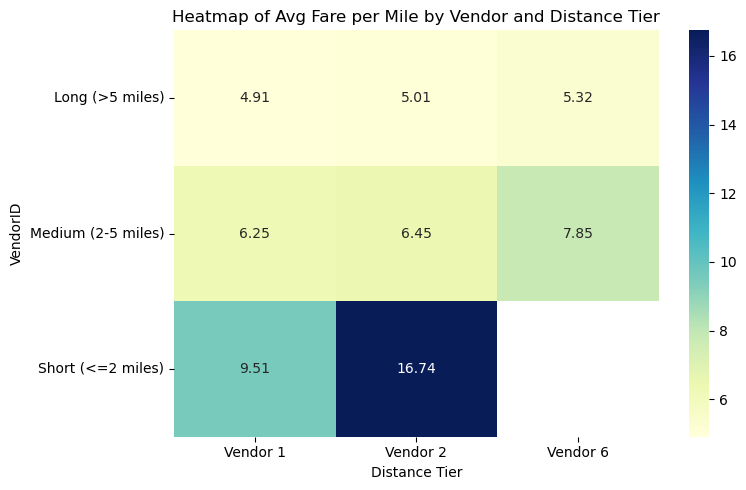

In [1111]:
# Plotting Average Fare by Vendor and Distance Tier

# Plotting a Heatmap 
plt.figure(figsize=(8,5))
sns.heatmap(fare_pivot, annot=True, cmap="YlGnBu", fmt=".2f")
plt.title("Heatmap of Avg Fare per Mile by Vendor and Distance Tier")
plt.ylabel("VendorID")
plt.xlabel("Distance Tier")
plt.tight_layout()
plt.show()

##### Customer Experience and Other Factors

**3.2.13** <font color = red>[5 marks]</font> <br>
Analyse average tip percentages based on trip distances, passenger counts and time of pickup. What factors lead to low tip percentages?

In [1115]:
#  Analyze tip percentages based on distances, passenger counts and pickup times
# Calculate tip percentage
# Avoid division by zero
df = df[df['fare_amount'] > 0]
df['tip_pct'] = (df['tip_amount'] / df['fare_amount']) * 100

In [1117]:
# Analyze by distances
tip_by_distance = df.groupby('distance_tier')['tip_pct'].mean().reset_index()
tip_by_distance

,distance_tier,tip_pct
0,Long (>5 miles),14.266591
1,Medium (2-5 miles),18.321284
2,Short (<=2 miles),22.217761


Insights:
- Passengers tend to tip a higher percentage for shorter trips and a lower percentage for longer trips.

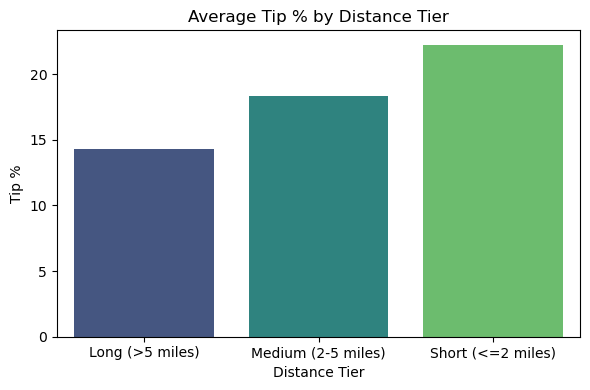

In [1120]:
# Plotting Tip % by Distance Tier
plt.figure(figsize=(6, 4))
sns.barplot(data=tip_by_distance, x='distance_tier', y='tip_pct', palette='viridis')
plt.title('Average Tip % by Distance Tier')
plt.ylabel('Tip %')
plt.xlabel('Distance Tier')
plt.tight_layout()
plt.show()

In [1122]:
# Analyze by Passenger Count
tip_by_passenger = df.groupby('passenger_count')['tip_pct'].mean().reset_index()
tip_by_passenger

,passenger_count,tip_pct
0,1,20.792112
1,2,20.168883
2,3,19.297387
3,4,17.793715
4,5,20.830647
5,6,21.094069


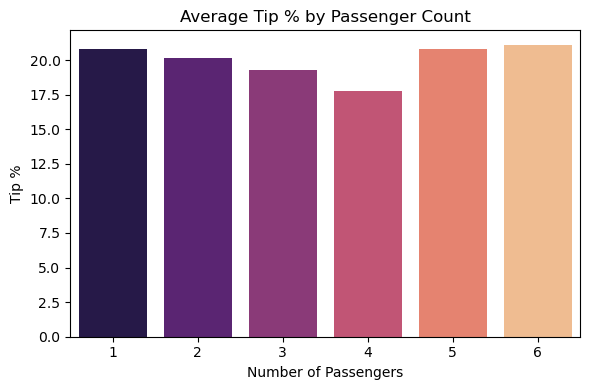

In [1124]:
# Plotting Tip % by Passenger Count
plt.figure(figsize=(6, 4))
sns.barplot(data=tip_by_passenger, x='passenger_count', y='tip_pct', palette='magma')
plt.title('Average Tip % by Passenger Count')
plt.ylabel('Tip %')
plt.xlabel('Number of Passengers')
plt.tight_layout()
plt.show()

In [1126]:
# Analyze by Pickup Hour
tip_by_hour = df.groupby('pickup_hour')['tip_pct'].mean().reset_index()
tip_by_hour

,pickup_hour,tip_pct
0,0,20.815318
1,1,21.094367
2,2,20.246541
3,3,19.896952
4,4,17.483526
5,5,17.952820
6,6,19.389329
7,7,19.865454
8,8,20.256322
9,9,19.829820


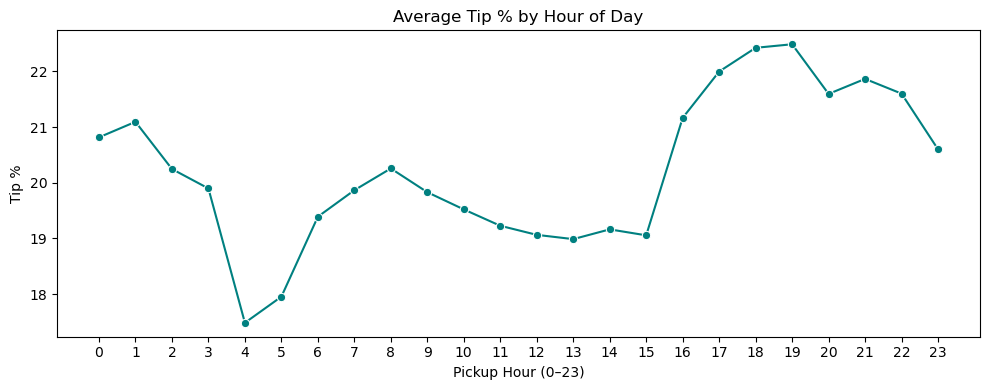

In [1128]:
# Tip % by Pickup Hour
plt.figure(figsize=(10, 4))
sns.lineplot(data=tip_by_hour, x='pickup_hour', y='tip_pct', marker='o', color='teal')
plt.title('Average Tip % by Hour of Day')
plt.ylabel('Tip %')
plt.xlabel('Pickup Hour (0–23)')
plt.xticks(range(0, 24))
plt.tight_layout()
plt.show()

Additional analysis [optional]: Let's try comparing cases of low tips with cases of high tips to find out if we find a clear aspect that drives up the tipping behaviours

In [1131]:
# Compare trips with tip percentage < 10% to trips with tip percentage > 25%

# Filter the trips with tip_pct < 10% and tip_pct > 25%
tip_less_than_10 = df[df['tip_pct'] < 10]
tip_greater_than_25 = df[df['tip_pct'] > 25]

# Comapring key metrics like average trip duration, average fare, etc.
tip_less_than_10_stats = tip_less_than_10[['trip_duration', 'fare_amount', 'tip_amount', 'total_amount']].mean()
tip_greater_than_25_stats = tip_greater_than_25[['trip_duration', 'fare_amount', 'tip_amount', 'total_amount']].mean()

In [1133]:
# Print the results
print("Trips with tip percentage < 10%:")
tip_less_than_10_stats

Trips with tip percentage < 10%:


trip_duration     0.222230
fare_amount      14.709401
tip_amount        0.195289
total_amount     19.567870
dtype: float64

In [1135]:
print("\nTrips with tip percentage > 25%:")
tip_greater_than_25_stats


Trips with tip percentage > 25%:


trip_duration     0.169690
fare_amount      11.389520
tip_amount        3.489549
total_amount     19.781742
dtype: float64

Insights:

- Shorter trips tend to have higher tip percentages: Despite the lower fare, customers tend to tip more generously on shorter trips.
- Longer trips tend to have lower tip percentages: Longer trips may be associated with lower tips, possibly due to longer ride durations affecting the perceived service quality or the cost of the fare.
- Total fare is similar for both groups, but the breakdown differs: Trips with a higher tip percentage tend to have lower fares but much higher tip amounts, while trips with a lower tip percentage have higher fares but much smaller tip amounts.

**3.2.14** <font color = red>[3 marks]</font> <br>
Analyse the variation of passenger count across hours and days of the week.

In [1139]:
# See how passenger count varies across hours and days

# Group by hour and calculate the mean or sum of passenger_count
hourly_passenger_count = df.groupby('pickup_hour')['passenger_count'].mean()

# Group by day of week and calculate the mean or sum of passenger_count
daily_passenger_count = df.groupby('day_of_week')['passenger_count'].mean()

# Pivot table to see the variation across hours and days
hour_day_variation = df.pivot_table(values='passenger_count', index='day_of_week', columns='pickup_hour', aggfunc='mean')

In [1141]:
# hourly_passenger_count
hourly_passenger_count

pickup_hour
0     1.396365
1     1.439417
2     1.422664
3     1.413687
4     1.321429
5     1.214953
6     1.196629
7     1.242696
8     1.276456
9     1.299671
10    1.343753
11    1.344316
12    1.355330
13    1.346823
14    1.369152
15    1.393754
16    1.380395
17    1.358746
18    1.363085
19    1.384011
20    1.384621
21    1.410758
22    1.432809
23    1.434438
Name: passenger_count, dtype: float64

In [1143]:
# daily_passenger_count
daily_passenger_count

day_of_week
Friday       1.391514
Monday       1.337997
Saturday     1.467136
Sunday       1.450788
Thursday     1.323310
Tuesday      1.315665
Wednesday    1.317187
Name: passenger_count, dtype: float64

In [1145]:
# hour_day_variation
hour_day_variation

pickup_hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
day_of_week,,,,,,,,,,,,,,,,,,,,,,,,
Friday,1.357622,1.348562,1.389049,1.392670,1.286822,1.193333,1.265882,1.288843,1.255622,1.302797,1.333752,1.306556,1.323430,1.321851,1.366041,1.388350,1.392874,1.381227,1.396975,1.435866,1.465260,1.511984,1.508916,1.482394
Monday,1.358247,1.415254,1.423729,1.600000,1.285714,1.142857,1.184444,1.235176,1.252907,1.294280,1.344758,1.336608,1.347642,1.312246,1.352782,1.387454,1.359580,1.313509,1.326567,1.364872,1.377078,1.372774,1.379282,1.354252
Saturday,1.448378,1.461591,1.483083,1.414348,1.306931,1.247706,1.162791,1.324051,1.345865,1.376022,1.414929,1.439038,1.462240,1.417196,1.421867,1.488338,1.444805,1.477171,1.486814,1.498444,1.443072,1.510460,1.539028,1.543430
Sunday,1.424804,1.488931,1.399107,1.408788,1.360526,1.380531,1.233503,1.292453,1.376114,1.435953,1.441267,1.422801,1.461495,1.436762,1.477596,1.500844,1.446299,1.454545,1.492179,1.488220,1.465347,1.454545,1.433431,1.473523
Thursday,1.329149,1.377049,1.331606,1.339286,1.264368,1.174497,1.183865,1.207317,1.282509,1.280731,1.294441,1.347666,1.288060,1.302863,1.336440,1.354697,1.357848,1.317045,1.288835,1.330120,1.331135,1.361893,1.402881,1.355193
Tuesday,1.347709,1.390805,1.333333,1.301887,1.372881,1.226027,1.156187,1.233469,1.272093,1.258119,1.298851,1.322474,1.309044,1.336265,1.333019,1.339640,1.326167,1.289015,1.305637,1.299787,1.318584,1.340513,1.369894,1.376955
Wednesday,1.364791,1.361868,1.419118,1.488636,1.296875,1.187919,1.201869,1.218650,1.251129,1.246070,1.316197,1.252083,1.303348,1.302037,1.313426,1.324215,1.346293,1.312744,1.309549,1.313694,1.339948,1.359240,1.367618,1.383330


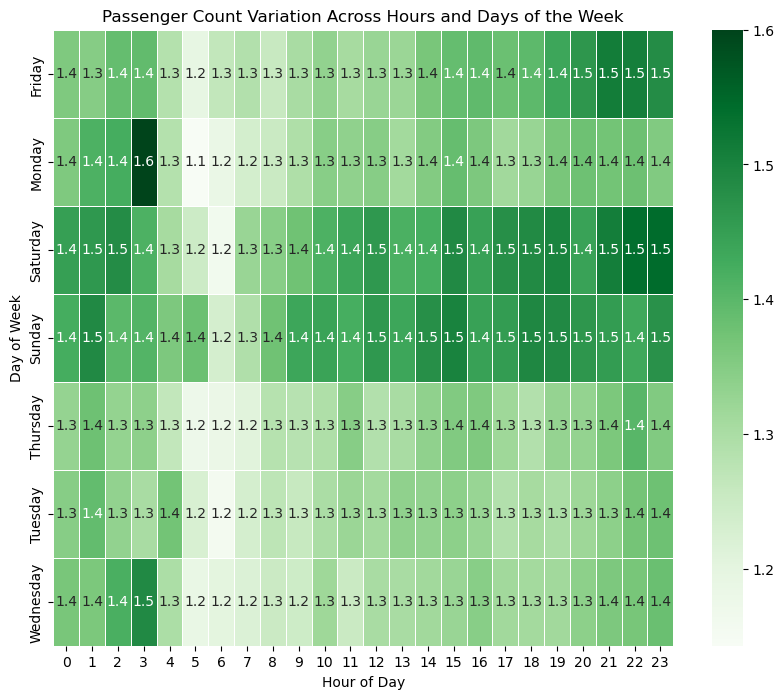

In [1147]:
# Plotting the heatmap for hour_day_variation
plt.figure(figsize=(10, 8))
sns.heatmap(hour_day_variation, cmap='Greens', annot=True, fmt='.1f', linewidths=0.5)
plt.title('Passenger Count Variation Across Hours and Days of the Week')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.show()

**3.2.15** <font color = red>[2 marks]</font> <br>
Analyse the variation of passenger counts across zones

In [1150]:
# How does passenger count vary across zones
# Group by zone
zone_passenger_counts = df.groupby('PU_zone')['passenger_count'].sum().sort_values(ascending=False)
zone_passenger_counts

PU_zone
Upper East Side South                  17569
Midtown Center                         17561
Upper East Side North                  15921
Times Sq/Theatre District              13354
Midtown East                           13350
Penn Station/Madison Sq West           13172
Lincoln Square East                    12987
Clinton East                           11176
Midtown North                          11010
Murray Hill                            10994
Upper West Side South                  10825
Union Sq                               10410
East Chelsea                           10286
East Village                           10202
West Village                            9246
Midtown South                           9056
Lenox Hill West                         9010
Gramercy                                8375
Sutton Place/Turtle Bay North           7202
Upper West Side North                   7153
Lenox Hill East                         7050
Central Park                            7026
Yo

In [1152]:
# For a more detailed analysis, we can use the zones_with_trips GeoDataFrame
# Create a new column for the average passenger count in each zone.

In [1154]:
# Step 1: Group trip data by PU_zone and calculate average passenger count
avg_passenger_per_zone = df.groupby('PU_zone')['passenger_count'].mean().reset_index()
avg_passenger_per_zone.columns = ['zone', 'avg_passenger_count']

# Step 2: Merge the average passenger count into the GeoDataFrame
gdf = merged_gdf.merge(avg_passenger_per_zone, on='zone', how='left')

In [1156]:
gdf.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 263 entries, 0 to 262
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype   
---  ------               --------------  -----   
 0   OBJECTID             263 non-null    int32   
 1   Shape_Leng           263 non-null    float64 
 2   Shape_Area           263 non-null    float64 
 3   zone                 263 non-null    object  
 4   LocationID           263 non-null    int32   
 5   borough              263 non-null    object  
 6   geometry             263 non-null    geometry
 7   total_trips          263 non-null    float64 
 8   avg_passenger_count  192 non-null    float64 
dtypes: float64(4), geometry(1), int32(2), object(2)
memory usage: 16.6+ KB


In [1158]:
gdf['avg_passenger_count'].describe()

count    192.000000
mean       1.337820
std        0.495528
min        1.000000
25%        1.000000
50%        1.281746
75%        1.397866
max        6.000000
Name: avg_passenger_count, dtype: float64

In [1160]:
gdf['avg_passenger_count'].isnull().sum()  # checking for null values

71

In [1162]:
gdf = gdf.dropna(subset=['avg_passenger_count'])

In [1164]:
top_zones = gdf[['zone', 'avg_passenger_count']].dropna().sort_values('avg_passenger_count', ascending=False).head(10)
bottom_zones = gdf[['zone', 'avg_passenger_count']].dropna().sort_values('avg_passenger_count', ascending=True).head(10)

In [1166]:
top_zones

,zone,avg_passenger_count
130,Jamaica Estates,6.000000
190,Queens Village,3.000000
123,Howard Beach,3.000000
146,Longwood,3.000000
196,Richmond Hill,2.500000
13,Bay Ridge,2.333333
218,Springfield Gardens South,2.250000
46,Claremont/Bathgate,2.200000
60,Crown Heights North,2.071429
38,Canarsie,2.000000


In [1168]:
bottom_zones

,zone,avg_passenger_count
226,Sunset Park East,1.0
88,Flatbush/Ditmas Park,1.0
184,Pelham Parkway,1.0
244,West Brighton,1.0
187,Prospect-Lefferts Gardens,1.0
76,East New York/Pennsylvania Avenue,1.0
70,East Flatbush/Farragut,1.0
195,Rego Park,1.0
68,East Concourse/Concourse Village,1.0
197,Ridgewood,1.0


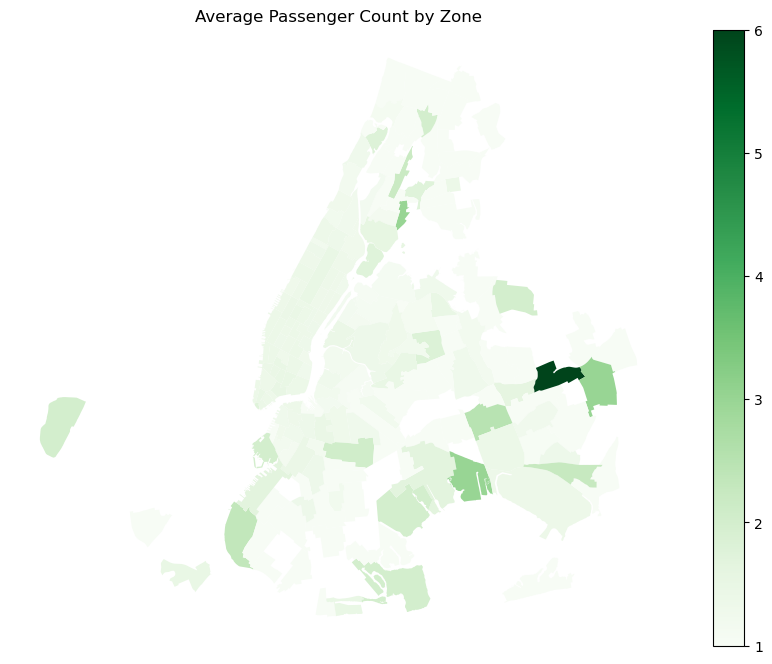

In [1170]:
gdf.plot(column='avg_passenger_count', cmap='Greens', legend=True, figsize=(12, 8))
plt.title('Average Passenger Count by Zone')
plt.axis('off')
plt.show()

Find out how often surcharges/extra charges are applied to understand their prevalance

**3.2.16** <font color = red>[5 marks]</font> <br>
Analyse the pickup/dropoff zones or times when extra charges are applied more frequently

In [1174]:
# How often is each surcharge applied?

In [1176]:
# df['extra'].value_counts()

In [1178]:
# Analyze extra charges by Pickup and Dropoff Zones

# Average extra charge by pickup zone
extra_by_PU = df.groupby('PU_zone')['extra'].mean().sort_values(ascending=False)

# Count of trips with extra charge > 0 by pickup zone
extra_count_PU = df[df['extra'] > 0].groupby('PU_zone')['extra'].count().sort_values(ascending=False)

# Similarly for dropoff zone
extra_by_DO = df.groupby('DO_zone')['extra'].mean().sort_values(ascending=False)

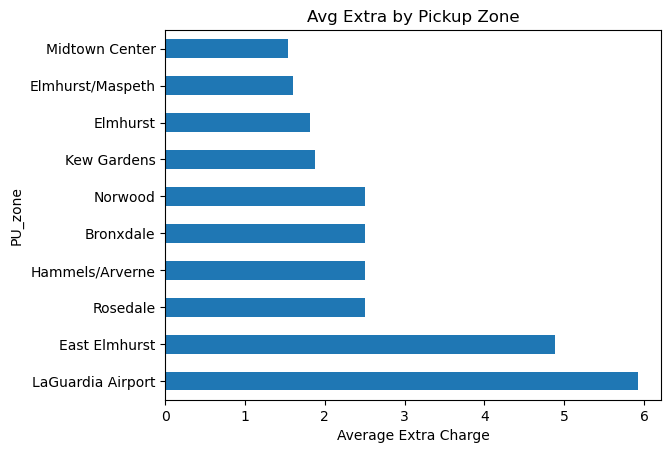

In [1180]:
extra_by_PU.head(10).plot(kind='barh', title='Avg Extra by Pickup Zone')
plt.xlabel('Average Extra Charge')
plt.show()

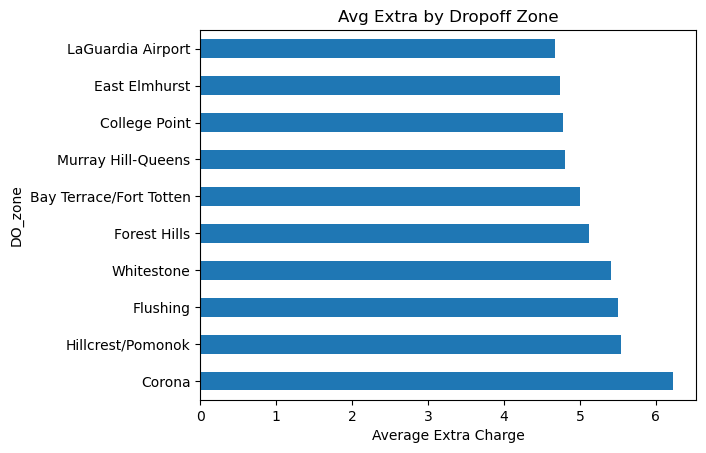

In [1182]:
extra_by_DO.head(10).plot(kind='barh', title='Avg Extra by Dropoff Zone')
plt.xlabel('Average Extra Charge')
plt.show()

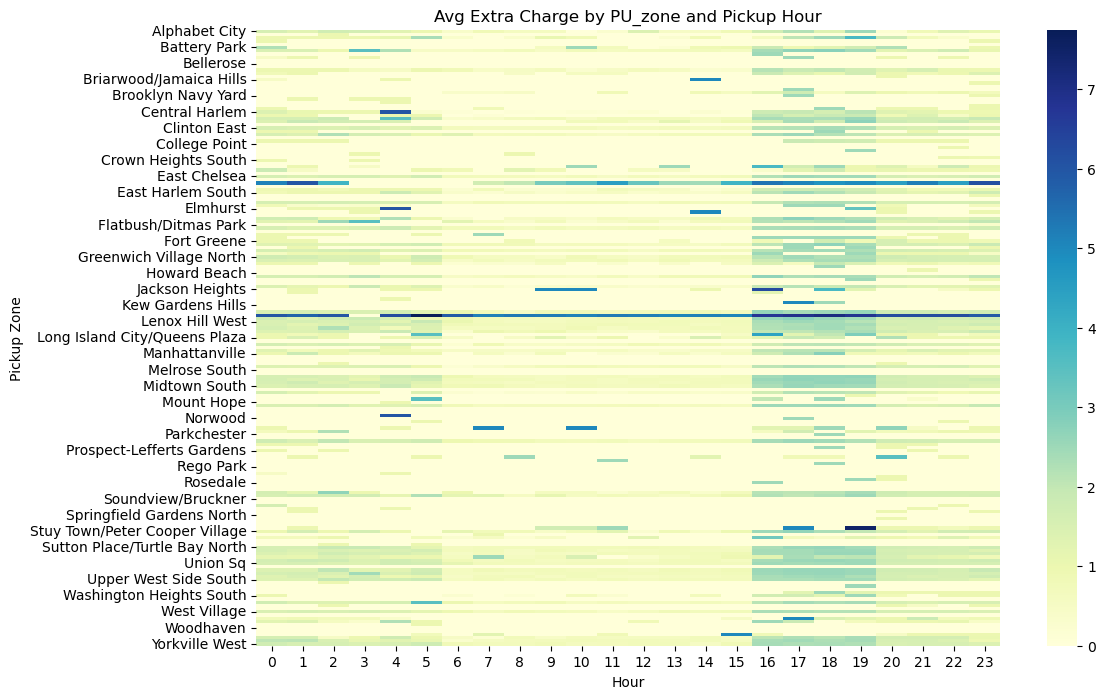

In [1184]:
# Average extra per pickup zone and hour
zone_hour_extra = df.groupby(['PU_zone', 'pickup_hour'])['extra'].mean().unstack().fillna(0)

# Heatmap
import seaborn as sns
plt.figure(figsize=(12,8))
sns.heatmap(zone_hour_extra, cmap="YlGnBu")
plt.title('Avg Extra Charge by PU_zone and Pickup Hour')
plt.xlabel('Hour')
plt.ylabel('Pickup Zone')
plt.show()

In [1185]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255526 entries, 0 to 255525
Data columns (total 32 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   VendorID               255526 non-null  int64         
 1   tpep_pickup_datetime   255526 non-null  datetime64[ns]
 2   tpep_dropoff_datetime  255526 non-null  datetime64[ns]
 3   passenger_count        255526 non-null  int32         
 4   trip_distance          255526 non-null  float64       
 5   RatecodeID             255526 non-null  int32         
 6   PULocationID           255526 non-null  int64         
 7   DOLocationID           255526 non-null  int64         
 8   payment_type           255526 non-null  object        
 9   fare_amount            255526 non-null  float64       
 10  extra                  255526 non-null  float64       
 11  mta_tax                255526 non-null  float64       
 12  tip_amount             255526 non-null  floa

In [1188]:
df.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee,date,pickup_hour,trip_duration,day_of_week,pickup_month,PU_zone,PU_borough,DO_zone,DO_borough,day_type,time_period,fare_per_mile,distance_tier,tip_pct
0,2,2023-01-01 00:16:41,2023-01-01 00:21:46,2,1.24,1,161,237,1,7.9,1.0,0.5,2.58,0.0,1.0,15.48,2.5,0.0,2023-01-01,0,0.084722,Sunday,2023-01,Midtown Center,Manhattan,Upper East Side South,Manhattan,Weekend,night,6.370968,Short (<=2 miles),32.658228
1,2,2023-01-01 00:14:03,2023-01-01 00:24:36,3,1.44,1,237,141,2,11.4,1.0,0.5,0.00,0.0,1.0,16.40,2.5,0.0,2023-01-01,0,0.175833,Sunday,2023-01,Upper East Side South,Manhattan,Lenox Hill West,Manhattan,Weekend,night,7.916667,Short (<=2 miles),0.000000
2,2,2023-01-01 00:24:30,2023-01-01 00:29:55,1,0.54,1,143,142,2,6.5,1.0,0.5,0.00,0.0,1.0,11.50,2.5,0.0,2023-01-01,0,0.090278,Sunday,2023-01,Lincoln Square West,Manhattan,Lincoln Square East,Manhattan,Weekend,night,12.037037,Short (<=2 miles),0.000000
3,2,2023-01-01 00:58:00,2023-01-01 01:08:31,2,1.59,1,79,164,1,11.4,1.0,0.5,3.28,0.0,1.0,19.68,2.5,0.0,2023-01-01,0,0.175278,Sunday,2023-01,East Village,Manhattan,Midtown South,Manhattan,Weekend,night,7.169811,Short (<=2 miles),28.771930
4,2,2023-01-01 00:16:06,2023-01-01 00:31:59,1,3.16,1,79,256,1,19.1,1.0,0.5,6.02,0.0,1.0,30.12,2.5,0.0,2023-01-01,0,0.264722,Sunday,2023-01,East Village,Manhattan,Williamsburg (South Side),Brooklyn,Weekend,night,6.044304,Medium (2-5 miles),31.518325


In [1190]:
# Analysing pickup/dropoff times when extra charges are applied more frequently

In [1192]:
# Filtering rows where extra charge is greater than 0
extra_charged_df = df[df['extra'] > 0]

In [1194]:
# Grouping by time-related columns to find frequency
# 1. By pickup hour
extra_by_hour = extra_charged_df['pickup_hour'].value_counts().sort_index()

In [1196]:
# 2. By time period (since there is day_type category)
extra_by_time_period = extra_charged_df['time_period'].value_counts()

In [1198]:
# 3. By day of the week
extra_by_day = extra_charged_df['day_of_week'].value_counts()

In [1200]:
# Proportion of trips with extra charges per pickup hour
total_by_hour = df['pickup_hour'].value_counts().sort_index()
proportion_by_hour = (extra_by_hour / total_by_hour).sort_values(ascending=False)

In [1202]:
proportion_by_hour

pickup_hour
21    0.981997
22    0.978522
20    0.973611
2     0.970368
23    0.970031
0     0.969604
3     0.961696
1     0.961398
4     0.938645
5     0.904465
18    0.794385
19    0.786776
17    0.784654
16    0.747247
6     0.301966
13    0.279152
7     0.278040
10    0.274913
15    0.273988
11    0.271499
9     0.270874
14    0.270645
8     0.266638
12    0.264421
Name: count, dtype: float64

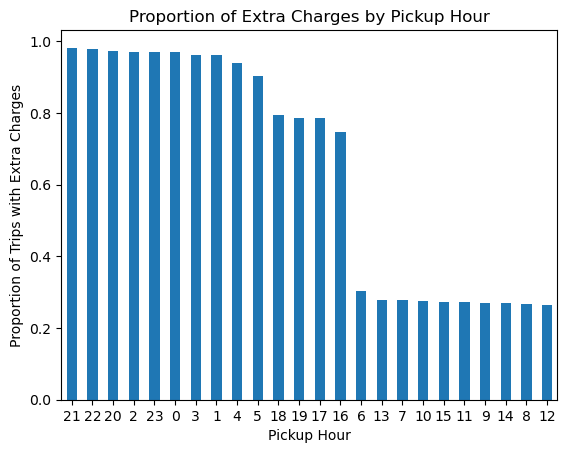

In [1204]:
# Plotting extra by pickup hour
proportion_by_hour.plot(kind='bar', title='Proportion of Extra Charges by Pickup Hour')
plt.xlabel('Pickup Hour')
plt.ylabel('Proportion of Trips with Extra Charges')
plt.xticks(rotation=0)
plt.show()

In [1206]:
# Proportion of trips with extra charges by time period
total_by_time_period = df['time_period'].value_counts().sort_index()
proportion_by_time_period = (extra_by_time_period / total_by_time_period).sort_values(ascending=False)
proportion_by_time_period

time_period
night    0.967918
day      0.560285
Name: count, dtype: float64

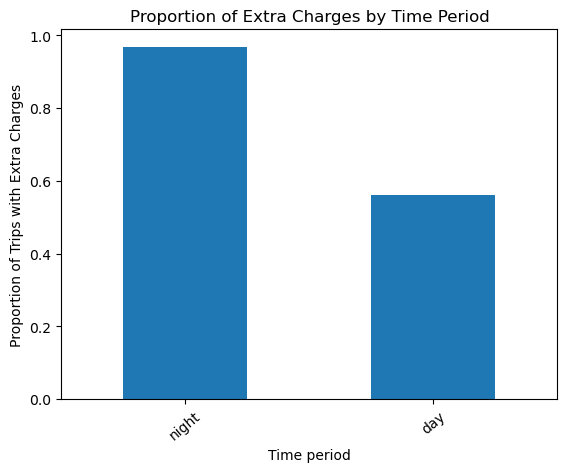

In [1208]:
# Plotting extra by time period
proportion_by_time_period.plot(kind='bar', title='Proportion of Extra Charges by Time Period')
plt.xlabel('Time period')
plt.ylabel('Proportion of Trips with Extra Charges')
plt.xticks(rotation=40)
plt.show()

In [1210]:
# Proportion of trips with extra charges by day of week
total_by_day_of_week = df['day_of_week'].value_counts().sort_index()
proportion_by_day_of_week = (extra_by_day / total_by_day_of_week).sort_values(ascending=False)
proportion_by_day_of_week

day_of_week
Friday       0.683464
Wednesday    0.669721
Thursday     0.668960
Tuesday      0.650619
Monday       0.630742
Saturday     0.561877
Sunday       0.526136
Name: count, dtype: float64

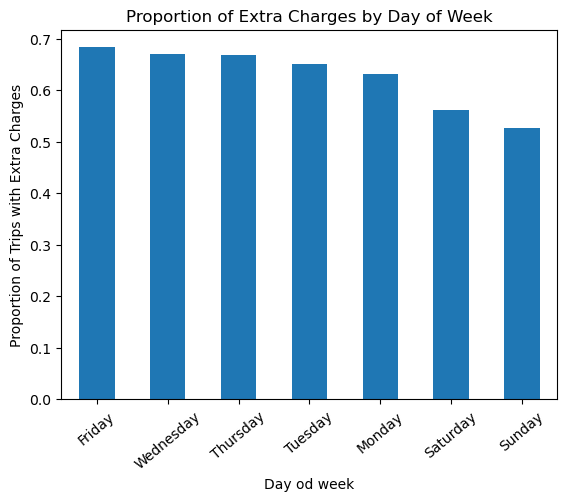

In [1212]:
# Plotting extra by day of week 
proportion_by_day_of_week.plot(kind='bar', title='Proportion of Extra Charges by Day of Week')
plt.xlabel('Day od week')
plt.ylabel('Proportion of Trips with Extra Charges')
plt.xticks(rotation=40)
plt.show()

## **4** Conclusion
<font color = red>[15 marks]</font> <br>

### **4.1** Final Insights and Recommendations
<font color = red>[15 marks]</font> <br>

Conclude your analyses here. Include all the outcomes you found based on the analysis.

Based on the insights, frame a concluding story explaining suitable parameters such as location, time of the day, day of the week etc. to be kept in mind while devising a strategy to meet customer demand and optimise supply.

**4.1.1** <font color = red>[5 marks]</font> <br>
Recommendations to optimize routing and dispatching based on demand patterns and operational inefficiencies

In [611]:
# Mentioned in the report

**4.1.2** <font color = red>[5 marks]</font> <br>

Suggestions on strategically positioning cabs across different zones to make best use of insights uncovered by analysing trip trends across time, days and months.

In [ ]:
# Mentioned in the report

**4.1.3** <font color = red>[5 marks]</font> <br>
Propose data-driven adjustments to the pricing strategy to maximize revenue while maintaining competitive rates with other vendors.

In [ ]:
# Mentioned in the report